# CIS342 課程專案 — 車牌辨識（License Plate Recognition, LPR）

**組別**：`6`

**組員**：
- `Ho Nok Hei` — `S26202765`（A 線）
- `Li Chi Shing` — `S26206590`（B 線）

**提交內容**：Jupyter notebook、PDF 報告、4 個成功案例、2 個失敗案例

**截止時間**：2026 年 12 月 18 日 12:00 中午（Moodle）

**簡報時間**：第 11 週起（暫定）

**評分比重**：程式執行 40% · 報告 30% · 現場簡報 30%



## 目錄

本 notebook 依課程要求的四個階段組織：**影像取得與資料準備 → 車牌偵測 → 字元辨識 → 後處理與驗證**，最後加上整合與評估。

**前置文件**

| 章節 | 內容 |
|---|---|
| AI 使用聲明（Ho Nok Hei） | 本人使用 AI 的方式與範圍 |
| AI 使用聲明（Li Chi Shing） | 另一位組員使用 AI 的方式與範圍 |
| 分工 | 兩人負責的章節與模組、整合窗口、時程 |
| 使用規則 | 協作方式與 cell 撰寫規範 |
| 進度 | 各階段完成狀態 |

**主體章節**

| 章節 | 內容 | 模組代號 | 對應流程階段 | 負責人 |
|---|---|---|---|---|
| §0 | 環境設置與共用資料契約 | `S0-1`～`S0-4` | 全階段共用 | Ho Nok Hei |
| §1 | 資料集取得、標註表與半自動標註 | `D1-01`～`D1-05` | 影像取得 | Ho Nok Hei |
| §2 | 前處理：光照補償與去噪 | `PRE-01` | 車牌偵測（前置） | Ho Nok Hei |
| §3 | 車牌定位：候選產生與篩選 | `LOC-01`、`LOC-02` | 車牌偵測 | Ho Nok Hei |
| §4 | 車牌擷取：由四邊形取出區域 | `SEG-01` | 車牌偵測 | Ho Nok Hei |
| §5 | 幾何校正：透視變換到固定尺寸 | `GEO-01` | 車牌偵測 | Ho Nok Hei |
| §6 | 字元辨識：二值化、切分與辨識 | `OCR-01`、`OCR-02` | 字元辨識 | Li Chi Shing |
| §7 | 後處理：字串規則修正與驗證 | `POST-01` | 後處理與驗證 | Li Chi Shing |
| §8 | 整合：全流程串接 | `INT-01` | 全流程 | Li Chi Shing |
| §9 | 評估：正確率與失敗案例分析 | `EV-01` | 全流程 | Li Chi Shing |


## AI 使用聲明（Ho Nok Hei）

> 本節由 Ho Nok Hei 自行維護，另一位組員請勿修改。
>
> ✏️ **【提交前填寫】** 補齊「使用的 AI 工具」的版本與日期範圍；並逐列確認表格內容是否與事實相符。

**組員**：`Ho Nok Hei`（`S26202765`）

**使用的 AI 工具**：GitHub Copilot（VS Code，Copilot SDK）

下表依時間順序記錄本人在本專案使用 AI 的方式。每一列都寫明「我下了什麼指令」、「AI 做了什麼」、「我如何驗證」、「最後由我決定什麼」。

| 工作部分 | 我給 AI 的輸入 | AI 的輸入與輸出 | 我驗證了什麼 | 我的最終決定／產出 |
|---|---|---|---|---|
| **筆記簿初始化與運行骨架定義**<br>§0 Setup、§1–§9 骨架 | 說明本專案為 2 人小組、以 `.ipynb` 在 Google Colab 協作（各自本機開發、以 cell 為單位貼上雲端）；要求先用 Python 3.12 建立 virtualenv；要求把實作內容劃分給兩人；並要求每次只增加一部分，避免一次產出無法理解的程式碼 | 讀取工作區既有檔案與課程 PDF（因無法直接讀 PDF，先轉為 Markdown）；產出 `TASK_DIVISION.md` 分工表；建立 `.venv`；產生 §0 Setup（import、共用常數、`Candidate` 資料契約、四點排序、影像讀取／除錯存圖／視覺化工具）以及 §1–§9 各階段函式 stub 與 `self test` cell | ✏️ **【提交前驗證】** 本人尚未親自執行。目前僅由 AI 以 `nbconvert --execute` 執行並回報「0 error cell」；需本人於 VS Code 重跑整份 notebook 確認 | 採用此骨架。`PLATE_W × PLATE_H` 暫定 `480 × 140`，待實際量測後調整；各階段先以簡化實作讓 pipeline 能端到端跑通 |
| **標題頁與文件書寫規範** | 要求移除「開發用 Notebook（本機）」這類內部說明；抬頭改為專案名稱、組別、組員姓名學號；標題一律放在 markdown cell 第一行；後續要求全文改用繁體中文 | 重寫標題頁與章節導覽表；把說明文字與程式註解改為繁體中文；修正簡體殘留與錯字 | 本人逐字閱讀並指出不當文字（如「開發用 Notebook」段落、表格化的抬頭），AI 依指示逐次修正 | 採用中文版；「A 線／B 線」代號僅保留於內部分工說明，對外（章節導覽、AI 聲明）改用組員姓名 |
| **AI 使用聲明表格格式** | 提供一份 AI 使用聲明的格式範例，要求 AI 依該範例的表格格式製作本專案的 AI 使用聲明；並指定欄位語意為「我給 AI 的輸入／AI 的輸入與輸出／我驗證了什麼／我的最終決定」 | 範例為 PDF，因無法直接讀取，改用 `pypdf` 提取表格文字；依範例的 5 欄結構製作聲明表格；後續依指示改為以組員姓名劃分而非 A/B 線 | 本人提供範例並確認欄位對應正確；表格內容是否與事實相符仍須本人逐列確認 | 採用範例的 5 欄格式，並以組員姓名作為節標題 |
| **章節編排與閱讀順序檢視** | 要求檢查「還有沒有其他排放順序不符合閱讀順序的地方」，並指出兩點：分工被排在 AI 聲明之後，評閱者不知 A／B 為何；把「分工」整節標為提交前刪除並不合理 | 列出 14 項排序與一致性問題（P1–P14）及建議順序；實際修正 §8 評估與 §9 整合的順序、補上章節導覽、補上「整合窗口」定義、分工表改用姓名 | 本人逐項判斷並採納大部分建議；部分項目（如 `DOC`/`CASE`/`PPT` 是否在 notebook 建章節）由本人決定 | 套用建議順序；§8 整合在前、§9 評估在後；標題頁加入章節導覽 |
| **開發用內容標記制度** | 要求「開發用標示內容」都要額外標示，指明是開發時用、未來需刪除或更改；並指出標記語意不應是「整節刪除」 | 設計三種標記：🛠️ 開發用｜提交前刪除、✏️ 提交前填寫、✏️ 提交前確認；套用至分工（段落級）、使用規則、進度、A／B 線開發順序表，以及 9 個 code cell 的 `TODO`／佔位註解 | 本人指出分工不應整節刪除，AI 已改為段落級標記並修正標記語意 | 採用三種標記；「分工」整節與 A／B 線章節標題列為必須保留 |
| **資料集來源評估與資料契約調整** | 提供兩個 Roboflow 資料集網址（33 張的 `hk-license-plate-recognition`、1,491 張的 `hk-fszrn`），詢問是否可用、能否辨識同圖多車牌、以及該用哪一個；並指定「先做單一車牌、但 labels.csv 預留欄位」 | 讀取頁面後回報：兩者授權皆 CC BY 4.0、皆為 Object Detection、**都沒有車牌字串**（仍需人工填）；33 張那集為 WhatsApp 壓縮轉傳、僅兩天拍攝；1,491 張那集為相機原圖。提出「B 為主（40–50）＋ A 作 external（10–15）」策略，並實作 `[D1-02]` COCO 匯入與 `[D1-03]` 半自動標註工具 | ✏️ **【提交前驗證】** 尚未驗證。圖片品質、實際可用張數與字串正確性仍須本人下載後逐張確認 | 採用 B 為主 ＋ A 為 external；`labels.csv` 新增 `plate_idx`、`split` 兩欄；本版 `run_pipeline()` 維持單一車牌輸出 |

**我未使用 AI 的部分**（以下為應由本人完成、目前尚未完成的事項）：

- **影像蒐集與實地拍攝**：包含前牌（白底）、後牌（黃底）、不同拍攝角度與光照條件的影像。
- **`labels.csv` 人工標註**：車牌字串、`front_rear`、`difficulty` 的判定與填寫。
- **實際執行與驗證**：於 VS Code 親自重跑整份 notebook，確認所有 cell 的輸出與上表「提交前驗證」欄的記載一致。
- **各階段演算法選型與調參**：前處理、車牌定位、擷取、幾何校正的方法選擇、參數調整與除錯（目前僅有 `TODO` 佔位實作）。
- **資料集最終取捨**：判斷是否採用 Roboflow 資料集、是否合併其他來源、以及要剔除哪些不可用影像。
- **報告撰寫與案例挑選**：方法論章節、4 個成功案例與 2 個失敗案例的選定與分析。

**責任聲明**：本人對本專案中所有提交的程式碼與結論負責。上表所述 AI 產出內容，在提交前均需由本人執行、理解與驗證；若發現錯誤由本人修正。

## AI 使用聲明（Li Chi Shing）

> 本節由 Li Chi Shing 自行填寫，另一位組員請勿代填。
>
> ✏️ **【提交前填寫】** 本節目前為空白模板。請依實際使用情況逐列填寫，不需要的列可刪除，
> 若有其他工作項目請自行新增列。填完後請把本段提示移除。

**組員**：`Li Chi Shing`（`S26206590`）

**使用的 AI 工具**：`<工具名稱與版本；若未使用 AI 請改寫為「無」>`

下表說明本人使用 AI 的方式。每一列填寫「我下了什麼指令」、「AI 做了什麼」、「我如何驗證」、「最後由我決定什麼」。

| 工作部分 | 我給 AI 的輸入 | AI 的輸入與輸出 | 我驗證了什麼 | 我的最終決定／產出 |
|---|---|---|---|---|
| `<工作部分 1>` | `<我向 AI 說明了什麼、要求它做什麼>` | `<AI 讀了什麼、產出了什麼>` | `<我實際檢查或執行了什麼>` | `<最後由我決定或採用的是什麼>` |
| `<工作部分 2>` | `<…>` | `<…>` | `<…>` | `<…>` |
| `<工作部分 3>` | `<…>` | `<…>` | `<…>` | `<…>` |

**我未使用 AI 的部分**：

- `<應由本人完成、且未使用 AI 的項目>`

**責任聲明**：本人對本專案中所有提交的程式碼與結論負責。AI 產出的內容均經本人理解、執行與驗證後才納入，若發現錯誤由本人修正。

## 分工

本專案由兩位組員共同完成，採「垂直切線」分工：以 pipeline 的四個必要階段為分界，
A 線負責「輸入影像 → 校正好的車牌圖」，B 線負責「校正車牌圖 → 字串」，
再各自延伸負責評估、整合與報告。

| 負責人 | 負責章節 | 對應 pipeline 階段 |
|---|---|---|
| **A 線**<br>`Ho Nok Hei`（`S26202765`） | §0 Setup、§1 資料集、§2 前處理、§3 車牌定位、§4 車牌擷取、§5 幾何校正 | 前處理、Localization、Segmentation、Geometric Transformation |
| **B 線**<br>`Li Chi Shing`（`S26206590`） | §6 字元辨識、§7 後處理、§8 整合、§9 評估 | OCR、後處理、全流程整合與評估 |

**其他交付項目**：`DOC`（PDF 報告）、`CASE`（4 個成功案例 + 2 個失敗案例）、`PPT`（現場簡報）由 B 線主導，
A 線提供各階段中間圖與失敗分析素材。這些內容屬獨立交付檔案，不在本 notebook 內。

> 🛠️ **【開發用｜提交前刪除】**
>
> 整合窗口：`Li Chi Shing`（B 線）。負責合併兩人 cell 進共用 Colab notebook、維護 §0 中標記 `[S0-2]` 的共用常數 cell，並負責最終提交。
> 其他人不直接改 `[S0-2]`，需要修改時先在群組提出。

> ✏️ **【提交前確認】** 確認上表姓名、學號與負責章節的對應正確。

## 使用規則

> 🛠️ **【開發用｜提交前刪除】** 本節只給組員看。刪除本節前請先確認沒有殘留任何標記。

1. 每個 cell 開頭都有 `# ==== [編號] 說明 ====` 標記，貼到 Colab 時**必須保留**。
2. **不要** `import` 本專案自己的 .py 檔（Colab 貼上會找不到）。所有函式都寫在 cell 內。
3. **不要修改別人的 cell**；§0 中標記 `[S0-2]` 的共用常數 cell 只有整合窗口能改。
4. 函式簽名必須符合 §0 中 `[S0-3]` 定義的資料契約，不得自行更改參數或回傳格式。
5. 標題（`#` / `##` / `###`）一律放在 markdown cell 第一行；需要新標題就另開 cell。
6. 缺少的套件在 Colab 用 `%pip install` 自行補，不要事先寫死在 notebook 裡。

**標記說明**：

- 🛠️ **【開發用｜提交前刪除】** — 只給組員看的內部流程說明。可能是一整節（如「使用規則」「進度」），
  也可能只是某節裡的其中一段（如「分工」裡的整合窗口說明）。**只刪標記所標示的那個段落，不要刪掉整節。**
- ✏️ **【提交前填寫／確認】** — 佔位或待確認內容，提交前必須補齊；填完後把標記本身移除。
- `# --- self test` 開頭的 cell — 開發期驗證用，提交前可保留作為示範，或整段刪除。

未加任何標記的內容即為正式內容，會原樣呈現給評閱者。

**必須保留、不可刪除**：`## 目錄`、兩節「AI 使用聲明」、`## 分工` 整節，以及「A 線：負責章節與開發順序」「B 線：負責章節與開發順序」
兩節的**標題與負責人資訊**。這些是評閱者判斷誰負責哪一部分的依據；
標題下方標記 🛠️ 的開發進度表才需要刪除。

## 進度

> 🛠️ **【開發用｜提交前刪除】** 本節只給組員看，用來追蹤各章節完成度。

**A 線（定位）**

- [x] **§0** Setup
- [ ] **§1** 資料集 / `labels.csv` / 半自動標註
- [ ] **§2** 前處理（PRE-01）
- [ ] **§3** 車牌定位（LOC-01 / LOC-02）
- [ ] **§4** 車牌擷取（SEG-01）
- [ ] **§5** 幾何校正（GEO-01）

**B 線（辨識／整合）**

- [ ] **§6** 字元辨識（OCR-01 / OCR-02）
- [ ] **§7** 後處理（POST-01）
- [ ] **§8** 整合（INT）
- [ ] **§9** 評估（EV）
- [ ] **DOC / CASE / PPT** 報告、案例、簡報

## §0 Setup

環境旗標、共用常數、資料契約與工具函式。
**本節必須先完整執行**，後續所有章節都依賴這裡的定義與路徑。

In [1]:
# ==== [S0-1] 共用 import 與環境旗標 ====
import os
import sys
import json
import re
import time
import shutil
import random
import zipfile
import tempfile
import glob
import hashlib
import unicodedata
import urllib.request
from dataclasses import dataclass, field
from typing import List, Tuple, Optional, Dict, Any

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

IN_COLAB = 'google.colab' in sys.modules

print('IN_COLAB', IN_COLAB)
print('Python', sys.version.split()[0])
print('OpenCV', cv2.__version__)
print('NumPy ', np.__version__)


IN_COLAB False
Python 3.12.10
OpenCV 5.0.0
NumPy  2.5.5


In [2]:
# ==== [S0-2] 共用常數與資料契約（全組共用，修改前請先討論） ====
# --- 目錄 ---
# 本機：往上找含 notebooks/ 的那一層當專案根目錄
# Colab：固定用 COLAB_ROOT，若資料放在 Google Drive 請改成掛載路徑
COLAB_ROOT = '/content'
def _find_root() -> str:
    """找出專案根目錄：Colab 用 /content，本機往上找含 notebooks/ 的那一層。"""
    if IN_COLAB:
        return COLAB_ROOT
    d = os.path.abspath('.')
    for _ in range(4):
        if os.path.isdir(os.path.join(d, 'notebooks')):
            return d
        parent = os.path.dirname(d)
        if parent == d:
            break
        d = parent
    return os.path.abspath('.')

PROJECT_ROOT = _find_root()
DATA_DIR     = os.path.join(PROJECT_ROOT, 'data', 'images')
RAW_DIR      = os.path.join(PROJECT_ROOT, 'data', 'raw')
LABELS_CSV   = os.path.join(PROJECT_ROOT, 'data', 'labels.csv')
DEBUG_DIR    = os.path.join(PROJECT_ROOT, 'debug')
SHARED_DIR   = os.path.join(PROJECT_ROOT, 'shared', 'rectified')
# §8 整合的 A→B 交接目錄：A 段寫入中間狀態，B 段用 glob 讀取（見 [INT-01] / [INT-02]）
STAGE_DIR    = os.path.join(PROJECT_ROOT, 'shared', 'stages')

# --- 幾何契約：所有階段看到的車牌尺寸都必須是這個 ---
PLATE_W, PLATE_H = 480, 140

# --- 定位參數 ---
TOP_K    = 5      # 最多保留幾個候選
MAX_SIDE = 1280   # 讀圖時限制最長邊，避免大圖拖慢

# --- 測試影像（自行指定要驗證的檔名）---
TEST_IMG = os.path.join(DATA_DIR, 'test_01.jpg')

# --- 標註難度標記 ---
# normal：可直接判讀（評分主力）
# hard  ：模糊／部分被遮／標註框不是車牌，但仍有可靠答案，保留在評估內
# unreadable：人眼亦不可判讀，text 刻意留空，評估時排除
# not_plate ：標註框不是車牌（保留給未來，目前無此值）
LABEL_DIFFICULTIES     = ('normal', 'hard', 'unreadable')
UNSCORABLE_DIFFICULTIES = ('unreadable', 'not_plate')   # 這些列沒有可靠標準答案

# --- 可重現性 ---
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

for _d in (DATA_DIR, RAW_DIR, os.path.dirname(LABELS_CSV), DEBUG_DIR, SHARED_DIR, STAGE_DIR):
    os.makedirs(_d, exist_ok=True)

print('PLATE =', PLATE_W, 'x', PLATE_H)
print('DATA_DIR =', DATA_DIR)
print('RAW_DIR  =', RAW_DIR)


PLATE = 480 x 140
DATA_DIR = C:\Users\honok\Desktop\cis342\project\data\images
RAW_DIR  = C:\Users\honok\Desktop\cis342\project\data\raw


### 資料契約結構

`Candidate` 是定位（LOC）與後續階段之間唯一的溝通格式。
`quad` 必須是 `(4,2) float32`、順時針、由左上開始 —— 用 `sort_quad()` 保證。


In [3]:
# ==== [S0-3] 資料契約：候選車牌結構 ====
@dataclass
class Candidate:
    """一個可能含車牌的四邊形候選。

    quad  : np.float32 (4,2)，順時針，由左上角開始
    score : 越大越可能是車牌
    source: 產生此候選的策略名稱（用於 ablation 與除錯）
    meta  : 其他除錯資訊（面積、矩形度、邊緣密度…）
    """
    quad: np.ndarray
    score: float = 0.0
    source: str = ''
    meta: Dict[str, Any] = field(default_factory=dict)

    @property
    def bbox(self) -> Tuple[int, int, int, int]:
        x, y, w, h = cv2.boundingRect(self.quad.astype(np.int32))
        return int(x), int(y), int(w), int(h)

    @property
    def aspect(self) -> float:
        _, _, w, h = self.bbox
        return w / max(h, 1)

    def crop(self, img: np.ndarray) -> np.ndarray:
        x, y, w, h = self.bbox
        return img[y:y + h, x:x + w].copy()


def sort_quad(pts: np.ndarray) -> np.ndarray:
    """四點排序為 左上 → 右上 → 右下 → 左下（順時針）。"""
    pts = np.asarray(pts, dtype=np.float32).reshape(4, 2)
    s = pts.sum(axis=1)
    d = np.diff(pts, axis=1).ravel()
    tl = pts[np.argmin(s)]
    br = pts[np.argmax(s)]
    tr = pts[np.argmin(d)]
    bl = pts[np.argmax(d)]
    return np.array([tl, tr, br, bl], dtype=np.float32)


In [4]:
# ==== [S0-4] 影像讀取、除錯輸出與視覺化工具 ====
def use_cjk_font() -> bool:
    """讓 matplotlib 能顯示中文標題。

    Colab 預設沒有中文字型，找不到時圖上標題會變成方框；
    此時改用英數標題，或在 Colab 先執行 `!apt-get -y install fonts-noto-cjk`。
    回傳是否成功設定。
    """
    from matplotlib import font_manager
    keywords = ('Noto Sans CJK', 'Noto Serif CJK', 'Microsoft JhengHei',
                'Microsoft YaHei', 'PingFang', 'Heiti', 'SimHei', 'WenQuanYi')
    available = {f.name for f in font_manager.fontManager.ttflist}
    for name in keywords:
        if name in available:
            plt.rcParams['font.sans-serif'] = [name] + plt.rcParams['font.sans-serif']
            plt.rcParams['axes.unicode_minus'] = False
            return True
    return False


HAS_CJK_FONT = use_cjk_font()
if not HAS_CJK_FONT:
    print('找不到中文字型，圖表標題請改用英數，或先執行 !apt-get -y install fonts-noto-cjk')


def load_image(path: str, max_side: int = MAX_SIDE) -> np.ndarray:
    """讀取影像（BGR）。最長邊超過 max_side 會等比縮小。"""
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f'讀不到影像：{path}')
    h, w = img.shape[:2]
    scale = max_side / max(h, w)
    if scale < 1.0:
        img = cv2.resize(img, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)
    return img


def pick_sample_image(seed: int = 0) -> Optional[str]:
    """挑一張實際存在的影像當測試圖。

    優先用 TEST_IMG（自行指定的驗證圖）；沒有就從 data/images/ 依檔名排序取第 seed 張。
    這樣各節的 self test 在資料匯入後就能直接跑，不必每次手動填路徑。
    """
    if os.path.exists(TEST_IMG):
        return TEST_IMG
    if not os.path.isdir(DATA_DIR):
        return None
    names = sorted(f for f in os.listdir(DATA_DIR)
                   if f.lower().endswith(('.jpg', '.jpeg', '.png')))
    if not names:
        return None
    return os.path.join(DATA_DIR, names[seed % len(names)])


def save_stage(case: str, stage: str, img: np.ndarray) -> str:
    """把某一階段的中間結果存到 debug/<case>/<stage>.png，回傳路徑。"""
    d = os.path.join(DEBUG_DIR, case)
    os.makedirs(d, exist_ok=True)
    p = os.path.join(d, f'{stage}.png')
    cv2.imwrite(p, img)
    return p


def save_case(case_name: str, stages: Dict[str, np.ndarray]) -> None:
    """一次存多個階段：stages = {'01_input': img, '02_pre': img, ...}"""
    for stage, im in stages.items():
        save_stage(case_name, stage, im)


def show(*imgs, titles=None, cols=3, size=4.2):
    """在 notebook 中並排顯示多張圖（支援 BGR 與灰階）。"""
    imgs = list(imgs)
    n = len(imgs)
    cols = min(cols, n)
    rows = int(np.ceil(n / cols))
    plt.figure(figsize=(cols * size, rows * size))
    for i, im in enumerate(imgs, 1):
        ax = plt.subplot(rows, cols, i)
        if im.ndim == 2:
            ax.imshow(im, cmap='gray', vmin=0, vmax=255)
        else:
            ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        ax.set_title(titles[i - 1] if titles and i - 1 < len(titles) else f'#{i}')
        ax.axis('off')
    plt.tight_layout()
    plt.show()


def draw_candidates(img: np.ndarray, cands: List[Candidate], top_k: int = TOP_K,
                    color=(0, 0, 255)) -> np.ndarray:
    """把候選四邊形畫在原圖上（除錯與報告用）。"""
    vis = img.copy()
    for i, c in enumerate(cands[:top_k]):
        cv2.polylines(vis, [c.quad.astype(np.int32)], True, color, 2)
        x, y, _, _ = c.bbox
        cv2.putText(vis, f'{i}:{c.score:.2f}', (x, max(y - 6, 12)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
    return vis


IN_COLAB     = False
PROJECT_ROOT = C:\Users\honok\Desktop\cis342\project
DEBUG_DIR    = C:\Users\honok\Desktop\cis342\project\debug
TEST_IMG     = C:\Users\honok\Desktop\cis342\project\data\images\test_01.jpg | 存在: False
bbox = (10, 10, 301, 99) | aspect = 3.04


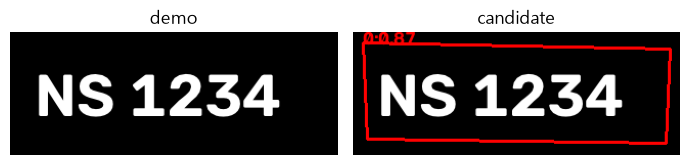

debug 圖已存到: C:\Users\honok\Desktop\cis342\project\debug\_selftest\00_demo.png


In [5]:
# --- self test: S0 環境檢查（不需要任何資料檔就能跑）---
print('IN_COLAB     =', IN_COLAB)
print('PROJECT_ROOT =', PROJECT_ROOT)
print('DEBUG_DIR    =', DEBUG_DIR)
print('TEST_IMG     =', TEST_IMG, '| 存在:', os.path.exists(TEST_IMG))

demo = np.zeros((120, 320, 3), np.uint8)
cv2.putText(demo, 'NS 1234', (24, 82), cv2.FONT_HERSHEY_SIMPLEX, 2, (255, 255, 255), 4)
q = np.float32([[10, 10], [310, 16], [306, 108], [14, 104]])
cand = Candidate(q, score=0.87, source='demo')
print('bbox =', cand.bbox, '| aspect =', round(cand.aspect, 2))
show(demo, draw_candidates(demo, [cand]), titles=['demo', 'candidate'], cols=2, size=3.5)

p = save_stage('_selftest', '00_demo', draw_candidates(demo, [cand]))
print('debug 圖已存到:', p)


## A 線：負責章節與開發順序（§1–§5）

**A 線（Localization 前段）**：`Ho Nok Hei`（`S26202765`）
負責「輸入影像 → 校正好的車牌圖」，即 §1 資料集至 §5 幾何校正。

> 🛠️ **【開發用｜提交前刪除】** 以下為 A 線的開發順序與交付內容，不屬於系統說明。

| 順序 | 章節 | 產出 | 解鎖誰 |
|---|---|---|---|
| 1 | **§1 資料集** | `data/images/*.jpg` + `data/labels.csv` | 全部（沒有圖無法驗證） |
| 2 | **§2 前處理** | `preprocess(img)` | §3 車牌定位 |
| 3 | **§3 車牌定位** | `localize_candidates()`、`localize()` | §4 車牌擷取、**B 線可開始接真資料** |
| 4 | **§4 車牌擷取** | `segment(img, quad)` | §5 幾何校正 |
| 5 | **§5 幾何校正** | `rectify(...)` → 存到 `shared/rectified/` | **B 線 OCR 開發** |

> ⚠️ 第 1 週結束前必須把「粗糙但能跑」的定位 + 幾何校正交出去（準確率低沒關係），否則 B 線會空轉一週。

## §1 資料集（D1）

所有影像放在 `data/images/`，標註集中寫在 `data/labels.csv`。§9 的評估只讀這一份標註。

**兩個測試集，分開計算**：

| 集合 | 張數 | 用途 |
|---|---|---|
| `main` | 100 | 主要結果。所有參數調整都在此集合上進行 |
| `external` | 10–15 | 外部來源、**未參與任何調參**，只用來證明非過擬合 |

兩者分開統計，不取總平均 —— 因為兩個來源的影像品質差異大（一為相機原圖、一為通訊軟體壓縮轉傳），
混合平均會掩蓋失誤來源。報告中分開呈現才有說服力。


### 資料集取得方式

本專案的影像與 `labels.csv` **未內嵌在 notebook 中**，而是在執行時下載。交付版本在 Google Colab 執行，
評閱者只要依序執行下列步驟，資料就會自動備妥，不需手動下載任何檔案。

| 步驟 | 模組 | 做什麼 |
|---|---|---|
| 1 | `[D1-04]` | 從 Roboflow 公開直連網址下載 COCO 壓縮檔到 `data/raw/`（**主要方式**，免 API key） |
| 1′ | `[D1-05]` | 上述失效時的備援：用 Google Drive 分享連結下載（免授權、免掛載） |
| 2 | `[D1-02]` | `check_raw_dir()` 確認結構與車牌類別 → `import_coco()` 隨機抽 100 張寫入 `data/images/` 與 `labels.csv` |
| 3 | `[D1-03]` | 逐張人工補上車牌字串、正反面、難度（成果存回 `labels.csv`） |
| 4 | `[D1-06]` | `labels.csv` 的 Drive 收送：組員／評閱者取回已填好的標註 |

`[D1-04]` 與 `[D1-05]` 只需執行其中一個 —— 兩者都會檢查 `data/raw/` 是否已有標註，
已有就自動略過，所以照順序全跑也不會重複下載。兩者共用同一套解壓與結構檢查邏輯。

| 對象 | 取得方式 |
|---|---|
| 評閱者（Colab） | 依上表執行，資料自動下載 |
| 組員（本機編輯） | 執行 `[D1-04]` 或 `[D1-05]` 取得影像，再用 `[D1-06]` 取回共用的 `labels.csv` |
| 沒有網路／連結失效 | `data/` 留空；§1 與 §9 會顯示「尚未建立 labels.csv，略過」，其餘章節需自行指定影像路徑 |

目錄結構：

```
data/
  images/       影像檔案（僅匯入的 100 張，由 [D1-02] 產生）
  labels.csv    標註表（人工填寫，由 [D1-06] 從 Drive 收送）
  raw/          下載解壓的完整 COCO 資料集（僅匯入時使用）
```


### 從 Roboflow 直連下載（主要方式）

Roboflow Universe 匯出後會給一條**免登入**的直連網址，用它抓 COCO 壓縮檔，不需要 API key，
也不會把任何憑證寫進 notebook。

**取得網址**：Roboflow Universe → 該資料集 → **Download Dataset** → 選 `COCO` →
複製頁面上的 `https://universe.roboflow.com/ds/...` 連結（形如 `https://universe.roboflow.com/ds/AbCd?key=XyZ`）。

**為什麼不用 API key 的 `roboflow` 套件**：notebook 會複製給組員、也會遞交給評閱者，
把 API key 寫在裡面等於把帳號額度一起交出去。直連網址本身就是公開下載連結，沒有這個問題。

> 下載後只做兩件事：解壓到 `data/raw/`、呼叫 `[D1-02]` 的 `import_coco()` 抽 100 張。
> 不做「取前 100 張」—— `import_coco()` 是固定種子**隨機**抽樣，避免 100 張全來自同一場景。

> ✏️ **【提交前確認】** 直連網址請確認仍可下載（Roboflow 改版可能失效）。
> 失效時改用下一節 `[D1-05]` 的 Drive 備援。


In [6]:
# ==== [D1-04] 從 Roboflow 直連下載 COCO 資料集 ====
# ✏️ 貼上 Roboflow「Download Dataset → COCO」頁面上的直連網址
ROBOFLOW_COCO_URL = '<貼上 Roboflow 直連下載網址>'

# 選填：記錄出處，供 §1 引用與報告使用
ROBOFLOW_DATASET = 'hk-fszrn (Safety Helmet Detection, Roboflow Universe)'


def has_coco(raw_dir: str = None) -> bool:
    """data/raw/ 底下是否已有 COCO 標註（用判斷要不要重新下載）。"""
    raw_dir = raw_dir or RAW_DIR
    return os.path.isdir(raw_dir) and any(
        '_annotations.coco.json' in fs for _r, _d, fs in os.walk(raw_dir))


def _merge_into(src: str, dst: str) -> None:
    """把 src 底下的檔案逐一覆蓋到 dst（同名目錄遞迴合併，不巢狀複製）。"""
    for name in os.listdir(src):
        s_path, d_path = os.path.join(src, name), os.path.join(dst, name)
        if os.path.isdir(s_path):
            os.makedirs(d_path, exist_ok=True)
            _merge_into(s_path, d_path)
        else:
            shutil.copyfile(s_path, d_path)


def _download_stream(url: str, dest: str, timeout: int = 600, label: str = '下載'):
    """把 url 內容串流寫入 dest，每 10% 印一次進度。

    回傳 (True, None)；若對方回傳的是 HTML（警告頁、權限錯誤）則回傳 (False, html)。
    """
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=timeout) as r:
        if 'text/html' in (r.headers.get('Content-Type') or ''):
            return False, r.read().decode('utf-8', 'ignore')
        total = int(r.headers.get('Content-Length') or 0)
        done, step = 0, 0
        with open(dest, 'wb') as f:
            while True:
                chunk = r.read(1 << 20)
                if not chunk:
                    break
                f.write(chunk)
                done += len(chunk)
                if total:
                    pct = done * 100 / total
                    if pct >= step + 10:
                        step = int(pct // 10 * 10)
                        print(f'{label} {pct:5.1f}%  {done / 1e6:6.0f} / {total / 1e6:.0f} MB')
            if total:
                print(f'{label} 完成  {done / 1e6:.0f} MB')
    return True, None


def extract_coco_zip(zip_path: str, raw_dir: str = None, remove_zip: bool = True) -> bool:
    """把 COCO 壓縮檔解壓到 data/raw/，並壓平多餘的外層資料夾。

    Roboflow / Google Drive 的 zip 常多包一層（如 hk-fszrn.coco/），
    壓平後 train/ valid/ test/ 才會直接位於 data/raw/ 之下。
    """
    raw_dir = raw_dir or RAW_DIR
    os.makedirs(raw_dir, exist_ok=True)
    with zipfile.ZipFile(zip_path) as zf:
        names = zf.namelist()
        zf.extractall(raw_dir)
    if remove_zip:
        try:
            os.remove(zip_path)
        except OSError:
            pass

    # 注意：不能用 shutil.move 搬目錄 —— 目標已存在時會搬進目標裡面（變成 train/train）
    tops = {n.split('/')[0] for n in names if '/' in n}
    if len(tops) == 1:
        top = os.path.join(raw_dir, tops.pop())
        if os.path.isdir(top):
            _merge_into(top, raw_dir)
            shutil.rmtree(top, ignore_errors=True)

    if not has_coco(raw_dir):
        print('⚠️ 解壓後找不到 _annotations.coco.json，請確認下載格式選的是 COCO')
        return False
    n = sum(1 for _r, _d, fs in os.walk(raw_dir) if '_annotations.coco.json' in fs)
    print(f'解壓完成：找到 {n} 份 COCO 標註，位於 {raw_dir}')
    print('下一步：執行 [D1-02] 的 check_raw_dir() 確認類別，再跑 import_coco()')
    return True


def download_coco(url: str = None, raw_dir: str = None, force: bool = False) -> bool:
    """下載 Roboflow COCO 壓縮檔並解壓到 data/raw/。

    - 免 API key：使用 Roboflow Universe 提供的公開直連網址
    - 已存在 _annotations.coco.json 時預設不重下（force=True 可強制）
    """
    url = url or ROBOFLOW_COCO_URL
    raw_dir = raw_dir or RAW_DIR

    if not url or url.startswith('<'):
        print('尚未設定 ROBOFLOW_COCO_URL')
        print('請到 Roboflow Universe → Download Dataset → COCO，複製直連網址填入本 cell 開頭')
        return False
    if has_coco(raw_dir) and not force:
        print('data/raw/ 已有 COCO 標註，略過下載（要重新下載請傳 force=True）')
        return True

    os.makedirs(raw_dir, exist_ok=True)
    fd, tmp_zip = tempfile.mkstemp(suffix='.zip')
    os.close(fd)
    print('下載中…')
    try:
        ok, html = _download_stream(url, tmp_zip)
        if not ok:
            print('下載失敗：回傳的是 HTML 頁面，通常代表網址需要登入或已失效')
            print('請確認網址可公開存取（瀏覽器無痕視窗貼上應能直接下載）')
            return False
    except Exception as e:
        print('下載失敗：', type(e).__name__, e)
        print('請確認網址可公開存取（瀏覽器無痕視窗貼上應能直接下載）')
        return False
    finally:
        if not os.path.exists(tmp_zip) or os.path.getsize(tmp_zip) == 0:
            if os.path.exists(tmp_zip):
                os.remove(tmp_zip)

    print(f'檔案大小 {os.path.getsize(tmp_zip) / 1024 / 1024:.1f} MB，解壓中…')
    return extract_coco_zip(tmp_zip, raw_dir)


In [7]:
# --- self test: [D1-04] ---
if download_coco():
    if 'check_raw_dir' in globals():
        check_raw_dir()
    else:
        print('資料集已就緒（結構檢查由 [D1-02] 的 check_raw_dir() 執行）')
else:
    print('尚未取得資料集，後續章節會顯示「略過」')


尚未設定 ROBOFLOW_COCO_URL
請到 Roboflow Universe → Download Dataset → COCO，複製直連網址填入本 cell 開頭
尚未取得資料集，後續章節會顯示「略過」


### 從 Google Drive 連結下載（備援）

當 `[D1-04]` 的 Roboflow 直連失效時，改用這裡。**不需要掛載 Drive、不需要授權**，
只要一條「知道連結的任何人可檢視」的分享連結即可。

**使用方式**：把 Drive 檔案的分享連結貼進 `[D1-05]`，執行後會自動下載並解壓到 `data/raw/`。

> 支援兩種輸入形式：
> - 分享連結：`https://drive.google.com/file/d/<ID>/view?usp=sharing`
> - 純檔案 ID：`<ID>`

**技術說明**：Drive 無法直接下載大型檔案 —— 會先回一個「病毒掃描警告」HTML 頁面，
要從裡面取出 `uuid` 再打第二次 `drive.usercontent.google.com/download`。本 cell 已處理這段。

> ✏️ **【提交前確認】** 連結權限需為「知道連結的任何人可檢視」，否則評閱者無法下載。


In [8]:
# ==== [D1-05] 從 Google Drive 分享連結下載資料集（備援） ====
DRIVE_SHARE_LINK = 'https://drive.google.com/file/d/1eCCV7C5rv4EZLN2uYHWp_ElY1zPDfHDX/view?usp=sharing'


def drive_id_from_link(link: str) -> str:
    """從 Google Drive 分享連結取出檔案 ID；若已是純 ID 則原樣回傳。"""
    link = (link or '').strip()
    m = re.search(r'/file/d/([A-Za-z0-9_-]{10,})', link)
    if m:
        return m.group(1)
    m = re.search(r'[?&]id=([A-Za-z0-9_-]{10,})', link)
    if m:
        return m.group(1)
    return link if re.fullmatch(r'[A-Za-z0-9_-]{10,}', link) else ''


def download_drive_zip(link: str = None, raw_dir: str = None, force: bool = False) -> bool:
    """用 Drive 分享連結下載壓縮檔並解壓到 data/raw/（不需掛載 Drive）。

    Drive 對大檔會先回「病毒掃描警告」HTML，需取出 uuid 後再打一次，
    帶 confirm=t 才會真的開始傳檔案。
    """
    link = link or DRIVE_SHARE_LINK
    raw_dir = raw_dir or RAW_DIR

    fid = drive_id_from_link(link)
    if not fid:
        print('無法從連結取出檔案 ID，請貼完整的 Drive 分享連結或純 ID')
        return False
    if has_coco(raw_dir) and not force:
        print('data/raw/ 已有 COCO 標註，略過下載（要重新下載請傳 force=True）')
        return True

    os.makedirs(raw_dir, exist_ok=True)
    fd, tmp_zip = tempfile.mkstemp(suffix='.zip')
    os.close(fd)

    base = 'https://drive.google.com/uc?export=download&id=' + fid
    print('下載中…')
    try:
        ok, html = _download_stream(base, tmp_zip, label='下載')
        if not ok:
            # 大型檔案：先取 confirm / uuid 再重試一次
            m_uuid = re.search(r'name="uuid"\s+value="([^"]+)"', html or '')
            m_conf = re.search(r'name="confirm"\s+value="([^"]+)"', html or '')
            if not (m_uuid and m_conf):
                print('下載失敗：回傳的是 HTML 頁面，且找不到 confirm 參數')
                print('常見原因：連結權限不是「知道連結的任何人可檢視」')
                return False
            retry = ('https://drive.usercontent.google.com/download'
                     f'?id={fid}&export=download&confirm={m_conf.group(1)}&uuid={m_uuid.group(1)}')
            print('檔案較大，需要確認下載（病毒掃描警告頁），自動重試…')
            ok, html = _download_stream(retry, tmp_zip, label='下載')
            if not ok:
                print('下載失敗：重試後仍取得 HTML 頁面，請確認連結權限')
                return False
    except Exception as e:
        print('下載失敗：', type(e).__name__, e)
        print('請確認連結可公開存取（瀏覽器無痕視窗貼上應能直接下載）')
        return False
    finally:
        if os.path.exists(tmp_zip) and os.path.getsize(tmp_zip) == 0:
            os.remove(tmp_zip)

    print(f'檔案大小 {os.path.getsize(tmp_zip) / 1024 / 1024:.1f} MB，解壓中…')
    return extract_coco_zip(tmp_zip, raw_dir)


In [9]:
# --- self test: [D1-05] ---
if download_drive_zip():
    if 'check_raw_dir' in globals():
        check_raw_dir()
    else:
        print('資料集已就緒（結構檢查由 [D1-02] 的 check_raw_dir() 執行）')
else:
    print('尚未取得資料集，後續章節會顯示「略過」')


data/raw/ 已有 COCO 標註，略過下載（要重新下載請傳 force=True）
資料集已就緒（結構檢查由 [D1-02] 的 check_raw_dir() 執行）


### 資料集來源與引用

本專案的影像來自 Roboflow Universe 上的公開資料集。兩者皆為 **CC BY 4.0** 授權，
依授權要求需標明原作者與出處。

| 用途 | 資料集 | 張數 | 授權 |
|---|---|---|---|
| 主要測試集（`main`） | [hk Computer Vision Dataset](https://universe.roboflow.com/safety-helmet-detection-lvkib/hk-fszrn) | 1,491（取 100 張） | CC BY 4.0 |
| 外部測試集（`external`） | [HK License Plate Recognition](https://universe.roboflow.com/hong-kong-license-plate-detect/hk-license-plate-recognition) | 33（取 10–15 張） | CC BY 4.0 |

主要測試集的建議引用格式（由 Roboflow 頁面提供）：

```bibtex
@misc{ hk-fszrn_dataset,
  title     = { hk Dataset },
  type      = { Open Source Dataset },
  author    = { Safety Helmet Detection },
  howpublished = { \url{ https://universe.roboflow.com/safety-helmet-detection-lvkib/hk-fszrn } },
  url       = { https://universe.roboflow.com/safety-helmet-detection-lvkib/hk-fszrn },
  journal   = { Roboflow Universe },
  publisher = { Roboflow },
  year      = { 2026 },
  month     = { apr },
  note      = { visited on 2026-11-19 }
}
```

> 兩份資料集都只提供**車牌邊界框**，不含車牌字串。`labels.csv` 的 `text` 欄由本組人工逐張填寫。


### `labels.csv` 欄位

| 欄位 | 型別 | 說明 |
|---|---|---|
| `file` | str | 影像檔名（不含路徑），例如 `IMG_5129.jpg` |
| `plate_idx` | str | 同一張圖的第幾個車牌；單車牌固定填 `0`（為多車牌擴充預留） |
| `split` | str | `main`（主要測試集）或 `external`（外部測試集，只用於交叉驗證，不參與調參） |
| `text` | str | 正確車牌字串，全大寫、**只留英數與中文**。`RDA•2388`、`RDA-2388`、`RDA 2388` 一律寫成 `RDA2388`（`save_label()` 會自動去除分隔符號） |
| `front_rear` | str | `front`（白底）或 `rear`（黃底） |
| `difficulty` | str | `normal` / `hard` / `unreadable`（語意見下） |
| `note` | str | 備註（側拍、陰影、部分遮擋、同圖含粵Z黑牌…），可留空 |

**車牌字串寫法**：

- 香港車牌印刷上常有中間圓點（`RDA•2388`）或連字號（`RDA-2388`），但**那不是字元**，
  只是排版分隔。`text` 只填真正的字元，即 `RDA2388`。
- 跨境車牌含中文字（如 `粵Z·1234`）時，中文保留、圓點去掉 → `粵Z1234`。
- 全部大寫，不要空白。`save_label()` 與 `import_coco()` 都遵循同一規則，
  所以手改 CSV 時也請照這個格式，否則 §9 評估會把它判成錯誤。

**`difficulty` 的意義**：

| 值 | 意義 | 是否計入 §9 準確率 |
|---|---|---|
| `normal` | 光線與角度正常，可直接判讀 | ✅ 計入（評分主力，89 張） |
| `hard` | 模糊、部分被遮、或標註框其實不是車牌，但仍判斷得出答案 | ✅ 計入（10 張） |
| `unreadable` | 人眼亦不可判讀（如車牌中間被反光白塊完全蓋住） | ❌ 排除（1 張） |
| `not_plate` | 標註框不是車牌（保留給未來，目前無此值） | ❌ 排除 |

`unreadable` 的列 **`text` 刻意留空**，代表「這是資料本身的限制，不是標錯」。
硬猜一個字串會製造假的標準答案，讓 §9 的準確率失真；整列刪掉又會讓樣本數
對不上 `labels.csv`。因此改用「保留該列、評估時排除」的做法，
並在報告中明確寫<|place_holder_mm_span_0442|>數量與排除理由（見 `TASK_DIVISION.md` §7）。

**單一車牌原則**：本版 `run_pipeline()` 每次只輸出一個車牌字串。若一張圖有多個車牌，
只標註**面積最大**的那一個（`[D1-02]` 已自動依此挑選），其餘視為背景。
`plate_idx` 是為日後擴充多車牌預留的欄位，現在每張圖只需一列。


In [10]:
# ==== [D1-01] 讀取標註表 ====
LABEL_COLUMNS = ['file', 'plate_idx', 'split', 'text', 'front_rear', 'difficulty', 'note']


def load_labels(path: str = LABELS_CSV) -> pd.DataFrame:
    """讀取 labels.csv，缺欄位會直接報錯，避免大家各寫各的格式。"""
    if not os.path.exists(path):
        return pd.DataFrame(columns=LABEL_COLUMNS)
    df = pd.read_csv(path, dtype=str).fillna('')
    missing = [c for c in LABEL_COLUMNS if c not in df.columns]
    if missing:
        raise ValueError(f'labels.csv 缺少欄位：{missing}')
    return df[LABEL_COLUMNS]


def file_sort_key(fname: str) -> str:
    """排序鍵：直接用檔名字串，從最左邊字元開始比。

    這樣 labels.csv 的列序才會跟檔案總管看到的順序一致 ——
    填標註時是一邊開著資料夾、一邊照順序往下填，順序對不上就要一直回頭找。
    """
    return str(fname)


def normalize_plate_text(text: str) -> str:
    """把使用者輸入的車牌字串正規化成統一格式。

    規則：全形轉半形（NFKC）→ 全大寫 → 只保留英數與中文。
    香港車牌印刷上常有中間圓點（RDA•2388）或連字號（RDA-2388），
    但那些只是排版分隔、不是字元；若不拿掉，§9 評估會把它們判成錯誤。
    跨境車牌的中文字（粵Z）要保留，所以不能只留 A-Z0-9。
    """
    s = unicodedata.normalize('NFKC', str(text)).upper()
    return re.sub(r'[^0-9A-Z\u4e00-\u9fff]', '', s)


FP_RE = re.compile(r'fp=([0-9a-f]{8})')


def _stamp_fp(note: str, fp: str) -> str:
    """把抽樣指紋寫進 note 欄（重複呼叫不會疊加）。"""
    note = FP_RE.sub('', str(note)).rstrip('; ')
    return (note + ';' if note else '') + f'fp={fp}'


def _labels_fingerprint(df=None) -> str:
    """從 labels.csv 的 note 欄讀出抽樣指紋；沒有記錄就回傳 ''。

    指紋是「這批影像是哪 100 張」的身分證。車牌字串只對這 100 張有效，
    換一批影像就等於沒有正確答案，所以指紋一定要跟著 labels.csv 走。
    """
    df = load_labels() if df is None else df
    if df is None or df.empty:
        return ''
    for v in df['note'].astype(str):
        m = FP_RE.search(v)
        if m:
            return m.group(1)
    return ''

In [11]:
# --- self test: [D1-01] ---
labels = load_labels()
print('labels.csv 筆數:', len(labels))
print('已存在的影像數:', len(os.listdir(DATA_DIR)) if os.path.isdir(DATA_DIR) else 0)
if len(labels):
    _fp = _labels_fingerprint(labels)
    print('抽樣指紋:', _fp or '(未記錄)')
    if not _fp:
        print('⚠️ labels.csv 沒有指紋（可能來自舊版）。填完標註前建議重跑一次 [D1-02] 讓它寫入。')
    display(labels.head())
else:
    print('尚未建立 labels.csv，欄位定義已就緒：', LABEL_COLUMNS)

labels.csv 筆數: 100
已存在的影像數: 100
抽樣指紋: bd1a4489


,file,plate_idx,split,text,front_rear,difficulty,note
0,train_IMG_1231_JPG.rf.4427265fe92179f31edca9a2...,0,main,RDA2388,rear,normal,"bbox=1755,1119,953,990;n_obj=1;cat=license_pla..."
1,train_IMG_1245_JPG.rf.a4ac20b643db2721c55399a1...,0,main,960GKF,rear,hard,"bbox=1074,1697,487,292;n_obj=4;cat=license_pla..."
2,train_IMG_4540_jpg.rf.1d98a6417d83bba5fb2d53e4...,0,main,GN2896,,normal,"bbox=1717,1696,629,161;n_obj=1;cat=license_pla..."
3,train_IMG_4553_jpg.rf.15c8f244a8448d91449e9705...,0,main,VF9219,,normal,"bbox=2158,1596,562,180;n_obj=3;cat=license_pla..."
4,train_IMG_4573_jpg.rf.ac29d744d644c98d63c1db6d...,0,main,T13225,,hard,"bbox=1538,1422,512,161;n_obj=1;cat=license_pla..."


In [12]:
# ==== [D1-02] 由 Roboflow COCO 標註匯入影像與 labels.csv 骨架 ====
# 用法：
#   1. 取得 COCO 資料集到 data/raw/（[D1-04] 直連下載，或 [D1-05] 從 Drive 同步）
#   2. 先跑 check_raw_dir() 確認結構與類別名稱
#   3. 再跑 import_coco() → 產生 data/images/* 與 data/labels.csv（text 留空）
#   4. 最後用 [D1-03] 逐張輸入車牌字串
# RAW_DIR 定義在 [S0-2] 共用常數
IMPORT_LIMIT_TOTAL = 100   # 總共匯入幾張（跨 train/valid/test 合計）
MIN_PLATE_W = 40           # 車牌寬度小於此值直接跳過（太小無法辨識，標了也用不上）
FORCE_RESAMPLE = False     # True＝即使指紋不符也強制重抽（會讓已填的 text 全部失效，慎用）

# 車牌類別名稱。留空＝自動判斷：單一類別直接用；多類別時用 plate / 車牌 / number 關鍵字猜。
# check_raw_dir() 印出的「車牌類別」欄若顯示「(不篩選)」或猜錯，就把正確名稱填在這裡。
# 本專案資料集（hk-fszrn v2）只有一個真正的標註類別：license_plate。
# 另一個 ploatew-license-plate 是 Roboflow 自動產生的父類別（supercategory），底下沒有標註，已自動排除。
PLATE_CATEGORY = 'license_plate'


def _plate_category_ids(coco: dict, want: str = '') -> Optional[set]:
    """挑出「車牌」類別的 category_id。回傳 None 代表不做類別篩選。

    資料集若同時標了安全帽、人、車等類別，不篩類別就會把最大框當成車牌 —— 這是錯的。
    """
    cats = coco.get('categories', [])
    if not cats:
        return None
    names = {c.get('id'): str(c.get('name', '')) for c in cats}

    if want:
        ids = {cid for cid, n in names.items() if want.lower() in n.lower()}
        if not ids:
            print(f'⚠️ 找不到類別「{want}」，實際類別：{list(names.values())}；改為自動判斷')
        else:
            return ids

    if len(names) == 1:
        return set(names)

    # Roboflow 會多塞一個父類別（supercategory='none'），它底下沒有任何標註，
    # 但名稱同樣含 plate，會讓「車牌類別」多一欄。把被別人當 supercategory 的排除。
    parents = {str(c.get('supercategory', '')) for c in cats} - {'none', ''}
    names = {cid: n for cid, n in names.items() if n not in parents}
    if not names:
        names = {c.get('id'): str(c.get('name', '')) for c in cats}
    if len(names) == 1:
        return set(names)

    keywords = ('plate', '車牌', 'number')
    ids = {cid for cid, n in names.items() if any(k in n.lower() for k in keywords)}
    if ids:
        return ids

    print(f'⚠️ 多類別但判斷不出哪個是車牌：{list(names.values())}')
    print('   請把類別名稱填入 PLATE_CATEGORY 後重跑；目前暫不篩選類別')
    return None


def check_raw_dir(raw_dir: str = None) -> pd.DataFrame:
    """列出 data/raw/ 底下找到的 COCO 標註檔、影像數量與車牌類別，確認結構正確。

    Roboflow 解壓後可能多包一層資料夾（例如 hk-fszrn.coco/），
    本函式會遞迴搜尋，不限固定層數。
    """
    raw_dir = raw_dir or RAW_DIR
    if not os.path.isdir(raw_dir):
        print(f'找不到 {raw_dir}')
        print('請先執行 [D1-04] 直連下載，或把資料集解壓到 data/raw/ 底下')
        return pd.DataFrame()

    rows = []
    for root, _dirs, files in os.walk(raw_dir):
        _dirs.sort()   # 固定順序，否則本機與 Colab 印出的 split 次序會不一樣
        if '_annotations.coco.json' not in files:
            continue
        ann_path = os.path.join(root, '_annotations.coco.json')
        with open(ann_path, encoding='utf-8') as f:
            coco = json.load(f)
        imgs = coco.get('images', [])
        anns = coco.get('annotations', [])
        # 實際存在的影像檔數
        present = sum(1 for im in imgs if os.path.exists(os.path.join(root, im['file_name'])))
        cats = [c.get('name', '?') for c in coco.get('categories', [])]
        ids = _plate_category_ids(coco, PLATE_CATEGORY)
        used = [c.get('name', '?') for c in coco.get('categories', []) if ids and c.get('id') in ids]
        rows.append({
            '資料夾': os.path.relpath(root, raw_dir),
            '影像(標註)': len(imgs),
            '影像(實際存在)': present,
            '標註框': len(anns),
            '類別': ', '.join(cats) if cats else '(無)',
            '車牌類別': ', '.join(used) if used else '(不篩選)',
        })

    if not rows:
        print(f'{raw_dir} 底下找不到 _annotations.coco.json')
        print('請確認解壓的是 COCO 格式，而不是 YOLO / VOC 格式')
        return pd.DataFrame()

    df = pd.DataFrame(rows)
    print(f'在 {raw_dir} 找到 {len(df)} 份 COCO 標註：')
    print(df.to_string(index=False))
    if (df['車牌類別'] == '(不篩選)').any():
        print('\n⚠️ 有資料夾未篩選類別，可能把非車牌物件當成車牌。')
        print('   請把「類別」欄中代表車牌的名稱填入 PLATE_CATEGORY 後重跑本 cell。')
    return df


def import_coco(raw_dir: str = None, limit_total: int = IMPORT_LIMIT_TOTAL,
                split_tag: str = 'main', min_plate_w: int = MIN_PLATE_W,
                seed: int = RANDOM_SEED, force_resample: bool = FORCE_RESAMPLE) -> pd.DataFrame:
    """把 Roboflow COCO 標註轉成本專案的 labels.csv 骨架。

    - 只取車牌類別的標註（避免抓到安全帽等其他物件）
    - 跨所有 split 收集後以固定種子隨機抽樣，避免只拿到某一類場景
    - 單一車牌原則：只取面積最大的車牌標註
    - 車牌太窄（< min_plate_w）或影像檔不存在者一律跳過
    - bbox 記在 note 欄，供 [D1-03] 顯示與日後重切使用
    - 重跑時不覆蓋已人工填寫的 text / front_rear / difficulty
    - 抽樣指紋寫進 note 並鎖定：指紋不符就拒絕重抽，避免 text 對錯影像
    """
    raw_dir = raw_dir or RAW_DIR
    if not os.path.isdir(raw_dir):
        print(f'找不到 {raw_dir}，請先執行 [D1-05] 下載或同步資料集')
        return pd.DataFrame(columns=LABEL_COLUMNS)

    pool, skipped = [], {'無標註': 0, '缺檔': 0, '車牌太小': 0}
    for root, dirs, files in os.walk(raw_dir):
        # 排序：os.walk 的順序隨檔案系統而異，不排序的話不同機器抽到的 100 張會不一樣
        dirs.sort()
        files.sort()
        if '_annotations.coco.json' not in files:
            continue
        split = os.path.basename(root).lower() or 'unknown'
        with open(os.path.join(root, '_annotations.coco.json'), encoding='utf-8') as f:
            coco = json.load(f)

        cat_ids = _plate_category_ids(coco, PLATE_CATEGORY)
        cat_name = {c.get('id'): str(c.get('name', '')) for c in coco.get('categories', [])}
        boxes = {}
        for a in coco.get('annotations', []):
            boxes.setdefault(a['image_id'], []).append(a)

        for im in coco.get('images', []):
            anns = boxes.get(im['id'], [])
            if cat_ids is not None:
                anns = [a for a in anns if a.get('category_id') in cat_ids]
            if not anns:
                skipped['無標註'] += 1
                continue
            best = max(anns, key=lambda a: a['bbox'][2] * a['bbox'][3])
            x, y, bw, bh = [int(round(v)) for v in best['bbox']]
            if bw < min_plate_w:
                skipped['車牌太小'] += 1
                continue
            src_img = os.path.join(root, im['file_name'])
            if not os.path.exists(src_img):
                skipped['缺檔'] += 1
                continue
            pool.append({
                'src': src_img,
                'name': f'{split}_{os.path.basename(im["file_name"])}',
                'note': (f'bbox={x},{y},{bw},{bh};n_obj={len(anns)};'
                         f'cat={cat_name.get(best.get("category_id"), "?")}'),
            })

    if not pool:
        print('沒有可匯入的影像，請先執行 check_raw_dir() 檢查結構與類別')
        return pd.DataFrame(columns=LABEL_COLUMNS)

    # 固定種子抽樣。抽樣前先依檔名排序 —— 否則 pool 的順序取決於檔案系統，
    # 同一份資料集在不同機器（本機 / Colab）會抽到不同的 100 張，
    # 導致 labels.csv 與影像對不上。
    pool.sort(key=lambda d: d['name'])
    random.Random(seed).shuffle(pool)
    picked = pool[:limit_total]

    # 抽樣指紋＝這批影像是哪 100 張的身分證。text 只對這批影像有效，
    # 所以指紋會寫進 note 並鎖定：換一批就代表所有 text 都要重填。
    fp = hashlib.md5('|'.join(sorted(d['name'] for d in picked)).encode()).hexdigest()[:8]
    if os.path.exists(LABELS_CSV) and not force_resample:
        locked = _labels_fingerprint()
        if locked and locked != fp:
            print(f'❌ 抽樣指紋不符：labels.csv 已鎖定 {locked}，本次抽到的是 {fp}。')
            print('   兩批影像不同，沿用舊 labels.csv 會讓 text 全部對錯圖片。')
            print('   請確認資料集版本與 RANDOM_SEED 沒有被改動；')
            print('   若真的想換一批（現有 text 全部作廢），先設 FORCE_RESAMPLE = True 再重跑。')
            return load_labels()
        if locked:
            print(f'抽樣指紋 {fp} 與 labels.csv 相符，重跑不會動到已填的 text。')

    os.makedirs(DATA_DIR, exist_ok=True)
    rows = []
    for item in picked:
        shutil.copyfile(item['src'], os.path.join(DATA_DIR, item['name']))
        rows.append({
            'file': item['name'],
            'plate_idx': '0',
            'split': split_tag,
            'text': '',          # 待人工填寫
            'front_rear': '',    # 待人工判斷
            'difficulty': '',    # 待人工判斷
            'note': _stamp_fp(item['note'], fp),
        })

    df = pd.DataFrame(rows, columns=LABEL_COLUMNS)
    dropped = 0
    if os.path.exists(LABELS_CSV):
        old = load_labels()
        # 已人工填過的值優先保留（重跑不可清空這些欄位）
        prev = old.drop_duplicates('file').set_index('file')
        for col in ('text', 'front_rear', 'difficulty'):
            keep = prev[col].astype(str).str.strip()
            filled = keep[keep != ''].to_dict()
            df[col] = [filled.get(f, v) for f, v in zip(df['file'], df[col])]
        # 這次沒抽到的舊列一律丟棄 —— labels.csv 必須剛好是本次抽樣結果，
        # 否則重跑會不斷累積、張數愈來愈多，與「main 100 張」的契約不符。
        gone = old[~old['file'].isin(df['file'])]
        dropped = len(gone)
        # 連影像檔一起清掉，否則 data/images/ 會殘留上一批的檔案。
        # 只刪「舊 labels.csv 有登記」的，自訂測試圖不會被動到。
        for fname in gone['file'].astype(str):
            fp_img = os.path.join(DATA_DIR, fname)
            if os.path.exists(fp_img):
                os.remove(fp_img)
        lost = gone[gone['text'].astype(str).str.strip() != '']
        if len(lost):
            print(f'⚠️ 有 {len(lost)} 筆已填好車牌字串的列不在本次抽樣中，將被移除：')
            print('   ', ', '.join(lost['file'].head(5)) + (' …' if len(lost) > 5 else ''))
            print('   若不想失去這些標註，請保留原 labels.csv 不要重跑匯入。')
    # 依檔名字串排序後才寫檔，打開 CSV 就與檔案總管顯示順序一致
    df = df.sort_values('file').reset_index(drop=True)
    df.to_csv(LABELS_CSV, index=False, encoding='utf-8-sig')

    print(f'候選 {len(pool)} 張，實際匯入 {len(rows)} 張｜抽樣指紋 {fp}')
    print('（指紋可用來確認本機與 Colab 抽到同一批影像；不一致就代表資料集版本不同）')
    if any(skipped.values()):
        print('已跳過：', '｜'.join(f'{k} {v} 張' for k, v in skipped.items() if v))
    if dropped:
        print(f'已移除 {dropped} 列不在本次抽樣中的舊資料')
    print(f'labels.csv 目前共 {len(df)} 列（text 待填）')
    return df


In [13]:
# --- self test: [D1-02] ---
check_raw_dir()
_df = import_coco()
if _df.empty:
    print('尚未匯入資料集（需要 data/raw/ 底下的 COCO 解壓結果）')
else:
    _todo = int((_df['text'].astype(str).str.strip() == '').sum())
    print(f'已標註 {len(_df) - _todo} 張，待填 text {_todo} 張')
    print('逐張填寫請用下一節的 [D1-03]')


在 C:\Users\honok\Desktop\cis342\project\data\raw 找到 2 份 COCO 標註：
  資料夾  影像(標註)  影像(實際存在)  標註框                                   類別          車牌類別
train    1044      1044 1232 ploatew-license-plate, license_plate license_plate
valid     447       447  548 ploatew-license-plate, license_plate license_plate


抽樣指紋 bd1a4489 與 labels.csv 相符，重跑不會動到已填的 text。


候選 1475 張，實際匯入 100 張｜抽樣指紋 bd1a4489
（指紋可用來確認本機與 Colab 抽到同一批影像；不一致就代表資料集版本不同）
已跳過： 車牌太小 16 張
labels.csv 目前共 100 列（text 待填）
已標註 99 張，待填 text 1 張
逐張填寫請用下一節的 [D1-03]


### 半自動標註

Roboflow 只給 bbox，**車牌字串必須人工填**。以下三個函式把流程縮到最短：
`label_progress()` 看剩多少 → `annotate_next()` 逐張填 → `save_label()` 可單筆手動補。

`annotate_next()` 需要 `ipywidgets`（Colab 內建；本機若無請先 `%pip install ipywidgets`）。
若無法使用，改用 `save_label('檔名.jpg', 'NS1234', 'front', 'normal')` 直接寫入。


In [14]:
# ==== [D1-03] 半自動標註工具 ====
def _parse_bbox(note: str):
    """從 note 欄的 bbox=x,y,w,h 取回座標。"""
    m = re.search(r'bbox=(-?\d+),(-?\d+),(\d+),(\d+)', note or '')
    return tuple(int(v) for v in m.groups()) if m else None


def sort_labels_csv(path: str = LABELS_CSV) -> pd.DataFrame:
    """把 labels.csv 依檔名數字重新排序後寫回（不改變任何內容）。"""
    df = load_labels(path)
    if df.empty:
        print('labels.csv 為空，略過排序')
        return df
    df = df.sort_values('file').reset_index(drop=True)
    df.to_csv(path, index=False, encoding='utf-8-sig')
    return df


def _is_labelled(df: pd.DataFrame) -> pd.Series:
    """是否已處理完畢：text 非空，或 difficulty 屬不可評分。

    unreadable 的列 text 刻意留空（見 labels.csv 欄位說明），
    若只看 text 是否空白，這些列會永遠顯示「未標註」。
    """
    has_text   = df['text'].astype(str).str.strip() != ''
    unscorable = df['difficulty'].astype(str).isin(UNSCORABLE_DIFFICULTIES)
    return has_text | unscorable


def label_progress(df: Optional[pd.DataFrame] = None) -> pd.DataFrame:
    """統計各 split 已處理／待處理的張數。

    已處理的定義見 _is_labelled()：填了 text，或標成 unreadable。
    """
    df = load_labels() if df is None else df
    if df.empty:
        print('labels.csv 為空，請先執行 [D1-02] 匯入資料集')
        return pd.DataFrame()
    df = df.copy()
    df['done'] = _is_labelled(df)
    tab = df.groupby('split')['done'].agg(總數='size', 已標註='sum')
    tab['未標註'] = tab['總數'] - tab['已標註']
    print(tab)
    return tab


def next_unlabeled(df: Optional[pd.DataFrame] = None) -> Optional[str]:
    """回傳下一張尚未填 text 的檔名。"""
    df = load_labels() if df is None else df
    if df.empty:
        return None
    todo = df[~_is_labelled(df)]
    if todo.empty:
        return None
    # 依檔名字串排序，與檔案總管顯示順序一致，才不用一直回頭找圖
    todo = todo.sort_values('file')
    return str(todo.iloc[0]['file'])


def show_label_target(fname: str, size: float = 7.0):
    """顯示要標註的影像並框出 bbox，方便對照打車牌字串。"""
    path = os.path.join(DATA_DIR, fname)
    if not os.path.exists(path):
        print(f'找不到影像：{path}')
        return None
    img = load_image(path)
    df = load_labels()
    row = df[df['file'] == fname]
    vis = img.copy()
    if not row.empty:
        bb = _parse_bbox(str(row.iloc[0]['note']))
        if bb:
            x, y, w, h = bb
            cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 0, 255), 2)
    # bbox 是原始座標，縮圖後需等比縮放才對得準
    h0, w0 = cv2.imread(path).shape[:2]
    sc = img.shape[1] / max(w0, 1)
    if sc < 1.0 and not row.empty:
        bb = _parse_bbox(str(row.iloc[0]['note']))
        if bb:
            vis = img.copy()
            x, y, w, h = [int(v * sc) for v in bb]
            cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 0, 255), 2)
    show(vis, titles=[fname], cols=1, size=size)
    return img


def save_label(fname: str, text: str, front_rear: str, difficulty: str,
               note: Optional[str] = None) -> None:
    """寫入或更新一筆標註。

    text 正規化為全大寫，並移除所有分隔符號 —— 含空白與各種中間圓點。
    香港車牌印刷上常見 `RDA•2388`、`RDA-2388`、`RDA 2388` 等寫法，
    但字串本身只有 `RDA2388`；若把圓點留下來，§9 評估會全部判成錯誤。
    """
    df = load_labels()
    if df.empty:
        print('labels.csv 為空，請先執行 [D1-02]')
        return
    clean = normalize_plate_text(text)
    if not clean and difficulty not in UNSCORABLE_DIFFICULTIES:
        print('text 不可為空（若影像真的不可判讀，difficulty 選 unreadable 再儲存）')
        return
    mask = df['file'].astype(str) == fname
    if not mask.any():
        print(f'labels.csv 沒有 {fname}，請確認檔名')
        return
    df.loc[mask, 'text'] = clean
    df.loc[mask, 'front_rear'] = front_rear
    df.loc[mask, 'difficulty'] = difficulty
    if note is not None:
        df.loc[mask, 'note'] = note
    df.to_csv(LABELS_CSV, index=False, encoding='utf-8-sig')
    print(f'已寫入：{fname} -> {clean} ({front_rear}, {difficulty})')


def annotate_next():
    """互動式逐張標註：顯示影像 → 輸入字串 → 儲存後自動跳下一張。"""
    try:
        import ipywidgets as widgets
        from IPython.display import display as _display, clear_output
    except ImportError:
        print('未安裝 ipywidgets，請執行 %pip install ipywidgets；'
              '或改用 save_label() 手動逐筆寫入')
        return None

    fname = next_unlabeled()
    if fname is None:
        print('全部標註完成')
        return None

    show_label_target(fname)
    box = widgets.Text(description='車牌：', placeholder='NS1234')
    fr = widgets.Dropdown(description='前/後：', options=['front', 'rear'])
    diff = widgets.Dropdown(description='難度：', options=list(LABEL_DIFFICULTIES), value='normal')
    btn = widgets.Button(description='儲存並下一張', button_style='success')
    out = widgets.Output()

    def _on_click(_):
        with out:
            clear_output()
            save_label(fname, box.value, fr.value, diff.value)
            label_progress()
        nxt = next_unlabeled()
        if nxt is None:
            print('全部標註完成')
        else:
            show_label_target(nxt)

    btn.on_click(_on_click)
    return _display(widgets.VBox([box, fr, diff, btn, out]))


In [15]:
# --- self test: [D1-03] ---
label_progress()
_nxt = next_unlabeled()
print('下一張待標註：', _nxt if _nxt else '（無，或標註已完成）')


        總數  已標註  未標註
split               
main   100  100    0
下一張待標註： （無，或標註已完成）


### `labels.csv` 的取得與回存

`labels.csv` 不會下載自資料集（Roboflow 只給標註框，不給車牌字串），它是**人工填寫**的成果，
所以另外放在 Google Drive，由本節負責收送。

- **下載**：`[D1-06]` 的 `LABELS_SHARE_LINK` 填 Drive 分享連結，執行 `download_labels()` 取回
- **回存**：填完後執行 `save_labels_to_drive()`；在 Colab 會直接存到 `/content/drive/...`，
  本機則用 `files.download()` 產出檔案由你手動上傳

> ✏️ **【提交前確認】** `LABELS_SHARE_LINK` 已填、權限為「知道連結的任何人可檢視」。

**為什麼要綁抽樣指紋**：`text` 是「第 N 張影像的正確答案」，換一批影像就全部對不上。
`[D1-02]` 會把抽樣指紋寫進 `note`（`fp=xxxxxxxx`）並鎖定，
`[D1-06]` 下載後也會比對 —— 指紋不符就停下來警告，不會讓你填了半天卻對錯圖片。


In [16]:
# ==== [D1-06] labels.csv 的 Drive 同步（下載 / 回存） ====
# labels.csv 是人工填寫的成果，不從資料集取得，因此單獨放在 Google Drive 收送。
# 建立方式：把填好的 data/labels.csv 上傳到 Drive，共用設為「知道連結的任何人可檢視」，
#           再把連結貼到下面（留空＝不同步，只使用本機的 data/labels.csv）。
LABELS_SHARE_LINK = 'https://drive.google.com/file/d/1AOZo8TyTXWugr4dYUqdU2bRrYS18cuJZ/view?usp=sharing'   # 例：'https://drive.google.com/file/d/<ID>/view?usp=sharing'


def download_labels(link: str = None, dest: str = None, force: bool = False) -> pd.DataFrame:
    """從 Drive 取回 labels.csv。本機已存在且非 force 時不動它。"""
    link = LABELS_SHARE_LINK if link is None else link
    dest = dest or LABELS_CSV

    if not (link or '').strip():
        print('未設定 LABELS_SHARE_LINK，沿用本機的 data/labels.csv')
        return load_labels()
    if os.path.exists(dest) and not force:
        print(f'{os.path.basename(dest)} 已存在，略過下載（要覆蓋請傳 force=True）')
        return load_labels()

    fid = drive_id_from_link(link)
    if not fid:
        print('無法從連結取出檔案 ID，請貼完整的 Drive 分享連結或純 ID')
        return load_labels()

    os.makedirs(os.path.dirname(dest) or '.', exist_ok=True)
    fd, tmp = tempfile.mkstemp(suffix='.csv')
    os.close(fd)
    base = 'https://drive.google.com/uc?export=download&id=' + fid
    print('下載 labels.csv…')
    try:
        ok, html = _download_stream(base, tmp, timeout=120, label='下載')
        if not ok:
            m_uuid = re.search(r'name="uuid"\s+value="([^"]+)"', html or '')
            m_conf = re.search(r'name="confirm"\s+value="([^"]+)"', html or '')
            if not (m_uuid and m_conf):
                print('下載失敗：回傳 HTML 頁面。請確認連結權限為「知道連結的任何人可檢視」')
                return load_labels()
            retry = ('https://drive.usercontent.google.com/download'
                     f'?id={fid}&export=download&confirm={m_conf.group(1)}&uuid={m_uuid.group(1)}')
            ok, html = _download_stream(retry, tmp, timeout=120, label='下載')
            if not ok:
                print('下載失敗：重試後仍取得 HTML 頁面，請確認連結權限')
                return load_labels()
        shutil.copyfile(tmp, dest)
    except Exception as e:
        print('下載失敗：', type(e).__name__, e)
        return load_labels()
    finally:
        if os.path.exists(tmp):
            os.remove(tmp)

    df = load_labels(dest)
    print(f'已取回 {len(df)} 列')

    # 指紋比對 —— 若這份 labels.csv 是為另一批影像填的，text 會全部對不上
    remote_fp = _labels_fingerprint(df)
    local_fp = _labels_fingerprint() if remote_fp else ''
    if remote_fp and local_fp and remote_fp != local_fp:
        print(f'⚠️ 指紋不符：這份 labels.csv 是 {remote_fp}，本機影像卻是 {local_fp}。')
        print('   車牌字串會對錯圖片，請確認是否拿錯檔案。')
    elif remote_fp:
        print(f'抽樣指紋 {remote_fp} 與本機影像相符')
    return df


def save_labels_to_drive(dest_dir: str = '/content/drive/MyDrive', name: str = 'labels.csv') -> bool:
    """把目前的 labels.csv 回存。Colab 有掛載 Drive 就寫進去，否則用瀏覽器下載。"""
    if not os.path.exists(LABELS_CSV):
        print('找不到 data/labels.csv，請先執行 [D1-02]')
        return False
    df = load_labels()
    fp = _labels_fingerprint(df)
    if fp:
        print(f'這份存檔鎖定抽樣指紋 {fp}（下載端指紋不符會警告）')

    if IN_COLAB:
        try:
            from google.colab import drive, files  # noqa: F401
            if not os.path.isdir('/content/drive/MyDrive'):
                print('Drive 尚未掛載，先執行：')
                print("    from google.colab import drive; drive.mount('/content/drive')")
                print('或直接用下一行把檔案下載到本機，再手動上傳到 Drive。')
                files.download(LABELS_CSV)
                print('已透過瀏覽器下載 labels.csv')
                return True
            out = os.path.join(dest_dir, name)
            os.makedirs(dest_dir, exist_ok=True)
            shutil.copyfile(LABELS_CSV, out)
            print(f'已回存到 {out}（{len(df)} 列）')
            return True
        except Exception as e:
            print('回存失敗：', type(e).__name__, e)
            return False

    print(f'本機環境：檔案在 {LABELS_CSV}，請手動上傳到 Google Drive 覆蓋舊檔。')
    return True


In [17]:
# --- self test: [D1-06] ---
_lab = download_labels()
print('目前 labels.csv 筆數:', len(_lab))
_fp = _labels_fingerprint(_lab)
print('抽樣指紋:', _fp or '(未記錄)')
if _fp and not os.path.isdir(DATA_DIR):
    print('⚠️ 有 labels.csv 但沒有 data/images/，請先執行 [D1-05] + [D1-02]')
if _fp:
    print('（指紋只在換資料集或改 RANDOM_SEED 時才會變 —— 那時 text 必須全部重填）')

labels.csv 已存在，略過下載（要覆蓋請傳 force=True）
目前 labels.csv 筆數: 100
抽樣指紋: bd1a4489
（指紋只在換資料集或改 RANDOM_SEED 時才會變 —— 那時 text 必須全部重填）


## §2 前處理（PRE-01）

目的是讓後續定位更穩定，例如光照補償、去噪、銳化。
**契約**：輸入原圖、輸出同尺寸 BGR 影像。

In [18]:
# ==== [PRE-01] 前處理：光照補償與去噪 ====
# 契約：輸入 BGR 原圖，輸出「同尺寸、同 dtype（uint8）」的 BGR 影像。
# 只能在可視性上改善，不可改變尺寸、不可裁切。
#
# 為什麼一定要留在 BGR：車牌正反面靠顏色區分（白底 front / 黃底 rear），
# 若在這裡就轉灰階或做色彩均衡，那份資訊就永遠拿不回來了。
# 需要灰階的階段（邊緣偵測、二值化）請各自在該節轉換。

PRE_CLAHE_CLIP = 2.0        # 對比增強的裁切上限；太大會把雜訊一起放大
PRE_CLAHE_GRID = (8, 8)     # 分區網格：越小越偏局部，適合不均勻光照
PRE_BILATERAL_D = 5         # 雙邊濾波鄰域直徑；5 對 1280px 影像已足夠
PRE_BILATERAL_SIGMA = 45    # 顏色/空間 sigma；越大越平滑
PRE_SHARPEN_AMOUNT = 0.6    # unsharp mask 強度；0 = 不銳化


def _compensate_illumination(bgr: np.ndarray) -> np.ndarray:
    """在 LAB 的 L（亮度）通道做 CLAHE。

    只動亮度、不動 a/b，所以白底車牌不會被推成偏藍、黃底也不會跑色。
    香港車牌常有單側陰影或背光，全圖直方圖均衡化會讓另一側過曝，分區 CLAHE 較穩。
    """
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    l = cv2.createCLAHE(clipLimit=PRE_CLAHE_CLIP, tileGridSize=PRE_CLAHE_GRID).apply(l)
    return cv2.cvtColor(cv2.merge([l, a, b]), cv2.COLOR_LAB2BGR)


def _denoise(bgr: np.ndarray) -> np.ndarray:
    """雙邊濾波：抹平雜訊，但保留車牌外框與字元筆畫的邊緣。

    不用高斯模糊，因為高斯會把車牌邊界一起糊掉 —— 而邊界正是 §3 定位要用的訊號。
    """
    return cv2.bilateralFilter(bgr, PRE_BILATERAL_D,
                               PRE_BILATERAL_SIGMA, PRE_BILATERAL_SIGMA)


def _sharpen(bgr: np.ndarray, amount: float = PRE_SHARPEN_AMOUNT) -> np.ndarray:
    """Unsharp mask：原圖 + amount ×（原圖 − 模糊圖），強化高頻邊緣。"""
    if amount <= 0:
        return bgr
    blur = cv2.GaussianBlur(bgr, (0, 0), 1.2)
    return cv2.addWeighted(bgr, 1.0 + amount, blur, -amount, 0)


def preprocess(img: np.ndarray, compensate: bool = True,
               denoise: bool = True, sharpen: bool = True) -> np.ndarray:
    """光照補償 → 去噪 → 銳化，回傳同尺寸 BGR 影像。

    三個旗標保留下來是為了做 ablation：報告裡要能回答
    「加了哪一步、準確率差多少」，而不是只能說「全部開了比較好」。
    """
    if img is None or img.size == 0:
        raise ValueError('preprocess 收到空影像')
    if img.ndim == 2:
        out = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    elif img.shape[2] == 4:
        out = cv2.cvtColor(img, cv2.COLOR_BGRA2BGR)
    elif img.shape[2] == 3:
        out = img
    else:
        raise ValueError(f'不支援的影像通道數：{img.shape}')

    out = out.copy()
    if compensate:
        out = _compensate_illumination(out)
    if denoise:
        out = _denoise(out)
    if sharpen:
        out = _sharpen(out)
    return out


測試圖 : train_IMG_1231_JPG.rf.4427265fe92179f31edca9a21230e353.jpg
shape  : (960, 1280, 3) -> (960, 1280, 3) | dtype uint8
對比(標準差)   59.0 ->   57.1
邊緣密度       4.89% ->   9.33%
平均 BGR 偏移  [18.  18.3 18.4] (過大會影響白底/黃底判斷)


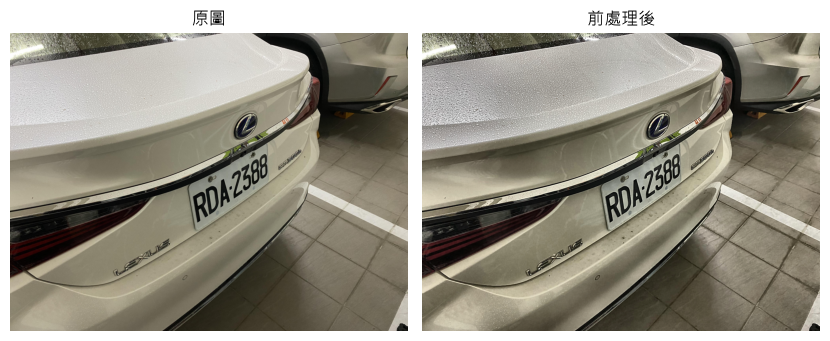


--- ablation（對比 / 邊緣密度）---
全部關閉   std=  59.0  edge= 4.89%
只光照補償  std=  55.5  edge= 9.70%
光照+去噪  std=  54.9  edge= 7.67%


全部開啟   std=  57.1  edge= 9.33%


In [19]:
# --- self test: [PRE-01] ---
_p = pick_sample_image()
if _p:
    _img = load_image(_p)
    _pre = preprocess(_img)

    # 契約檢查：尺寸與 dtype 都不可變
    assert _pre.shape == _img.shape, f'契約破壞：尺寸 {_img.shape} -> {_pre.shape}'
    assert _pre.dtype == np.uint8, f'契約破壞：dtype {_pre.dtype}'

    _g0 = cv2.cvtColor(_img, cv2.COLOR_BGR2GRAY)
    _g1 = cv2.cvtColor(_pre, cv2.COLOR_BGR2GRAY)
    _e0 = (cv2.Canny(_g0, 100, 200) > 0).mean() * 100
    _e1 = (cv2.Canny(_g1, 100, 200) > 0).mean() * 100

    print('測試圖 :', os.path.basename(_p))
    print('shape  :', _img.shape, '->', _pre.shape, '| dtype', _pre.dtype)
    print(f'對比(標準差) {_g0.std():6.1f} -> {_g1.std():6.1f}')
    print(f'邊緣密度     {_e0:6.2f}% -> {_e1:6.2f}%')

    # 顏色是否被推走：用平均 BGR 差衡量（過大代表白/黃底被改色，會影響正反面判斷）
    _shift = np.abs(_pre.astype(np.int16) - _img.astype(np.int16)).mean(axis=(0, 1))
    print('平均 BGR 偏移 ', np.round(_shift, 1), '(過大會影響白底/黃底判斷)')

    save_case('PRE-01', {'01_input': _img, '02_pre': _pre})
    show(_img, _pre, titles=['原圖', '前處理後'], cols=2)

    # ablation：關掉各步驟看差異，報告可直接引用
    print('\n--- ablation（對比 / 邊緣密度）---')
    for _name, _kw in [('全部關閉', dict(compensate=False, denoise=False, sharpen=False)),
                       ('只光照補償', dict(denoise=False, sharpen=False)),
                       ('光照+去噪', dict(sharpen=False)),
                       ('全部開啟', dict())]:
        _v = preprocess(_img, **_kw)
        _vg = cv2.cvtColor(_v, cv2.COLOR_BGR2GRAY)
        print(f'{_name:<6} std={_vg.std():6.1f}  edge={(cv2.Canny(_vg,100,200)>0).mean()*100:5.2f}%')
else:
    print('尚未提供測試圖，略過（或先執行 [D1-02] 匯入影像）')


## §3 車牌定位（LOC-01 / LOC-02）

分成兩步：先**產生候選**（寧可多、不可漏），再**評分篩選**（排序取 top-k）。
最終對外只暴露 `localize()`，回傳 `List[Candidate]`，分數由高到低。

In [20]:
# ==== [LOC-01] 定位：候選產生 ====
def localize_candidates(img: np.ndarray) -> List[Candidate]:
    """產生所有可能是車牌的四邊形候選（不評分、不篩選）。

    建議方向：白牌／黃牌色彩模型 → 灰階 → 形態學閉運算 → findContours 取四邊形。
    """
    # 🛠️ [開發用] TODO: 實作候選產生
    return []

In [21]:
# ==== [LOC-02] 定位：候選評分與篩選 ====
def localize(img: np.ndarray) -> List[Candidate]:
    """對候選評分並回傳前 TOP_K 個，分數由高到低。

    評分可考慮：長寬比、面積、矩形度、內部邊緣密度、黑白對比度。
    """
    cands = localize_candidates(img)
    # 🛠️ [開發用] TODO: 實作評分與排序
    return sorted(cands, key=lambda c: c.score, reverse=True)[:TOP_K]

In [22]:
# --- self test: [LOC-01] / [LOC-02] ---
if os.path.exists(TEST_IMG):
    _img = preprocess(load_image(TEST_IMG))
    _cands = localize(_img)
    print('候選數:', len(_cands))
    for _c in _cands:
        print(f'  score={_c.score:.3f} aspect={_c.aspect:.2f} source={_c.source}')
    show(draw_candidates(_img, _cands), titles=['候選'], cols=1, size=7)
else:
    print('尚未提供測試圖，略過')

尚未提供測試圖，略過


## §4 車牌擷取（SEG-01）

以定位給的 `quad` 為基礎，精修邊界並產生車牌區域遮罩。
**契約**：`segment(img, quad)` → `(plate_bgr, mask_uint8)`；輸入為**原始影像**，不是前處理後的圖。

In [23]:
# ==== [SEG-01] 擷取：由四邊形取出車牌區域 ====
def segment(img: np.ndarray, quad: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    """依四點取出車牌區域。

    plate_bgr : 車牌區域影像（尚未校正透視）
    mask_uint8: 同尺寸遮罩，255 = 車牌像素
    """
    q = sort_quad(quad)
    # 🛠️ [開發用] TODO: 精修邊界並產生遮罩
    plate = img[int(q[:, 1].min()):int(q[:, 1].max()), int(q[:, 0].min()):int(q[:, 0].max())].copy()
    mask = np.full(plate.shape[:2], 255, np.uint8)
    return plate, mask

In [24]:
# --- self test: [SEG-01] ---
if os.path.exists(TEST_IMG):
    _img = load_image(TEST_IMG)
    _cands = localize(preprocess(_img))
    if _cands:
        _plate, _mask = segment(_img, _cands[0].quad)
        print('plate', _plate.shape, '| mask', _mask.shape)
        show(_plate, _mask, titles=['車牌區域', '遮罩'], cols=2)
    else:
        print('沒有候選，略過')
else:
    print('尚未提供測試圖，略過')

尚未提供測試圖，略過


## §5 幾何校正（GEO-01）

把車牌校正成正視圖，輸出尺寸固定為 `PLATE_W × PLATE_H`（定義在 `[S0-2]`）。
**契約**：`rectify(plate_bgr, mask)` → `(upright_bgr, upright_mask)`。

In [25]:
# ==== [GEO-01] 幾何校正：透視變換到固定尺寸 ====
def rectify(plate_bgr: np.ndarray, mask: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    """校正透視變形，輸出 PLATE_W × PLATE_H 的正視車牌。

    這一步的輸出是 B 線 OCR 的唯一輸入，尺寸與極性都必須穩定。
    """
    # 🛠️ [開發用] TODO: 找四角 → getPerspectiveTransform → warpPerspective
    up = cv2.resize(plate_bgr, (PLATE_W, PLATE_H), interpolation=cv2.INTER_LINEAR)
    up_mask = cv2.resize(mask, (PLATE_W, PLATE_H), interpolation=cv2.INTER_NEAREST)
    return up, up_mask

In [26]:
# --- self test: [GEO-01] ---
if os.path.exists(TEST_IMG):
    _img = load_image(TEST_IMG)
    _cands = localize(preprocess(_img))
    if _cands:
        _plate, _mask = segment(_img, _cands[0].quad)
        _up, _up_mask = rectify(_plate, _mask)
        print('rectified', _up.shape)
        show(_plate, _up, titles=['擷取', '校正後'], cols=2)
    else:
        print('沒有候選，略過')
else:
    print('尚未提供測試圖，略過')

尚未提供測試圖，略過


## §5.5 整合（A 段｜`INT-01`）：A 線全流程與中間狀態輸出

> **§8 整合已拆為兩段。** 完整整合章節 = 本節（A 段，A 線出口）＋ §8（B 段，B 線入口）。
>
> 拆開是因為兩人可以並行：A 段跑完把中間狀態寫成**檔案**，B 段不必等 A 段的程式完成，
> 只要讀檔案就能開發與測試，也不需要同一個 kernel、同一台機器。
> 本節放在 A 線末尾而非 §8，是為了讓程式碼與它所屬的章節（§1–§5）連續，避免閱讀時跳號。

把前處理 → 定位 → 擷取 → 校正串成 `run_frontend()`，並由 `export_frontend()`
把每個階段的中間圖寫到 `shared/stages/`。

**契約**：`run_frontend(img, quad=None)` → `{'ok', 'reason', 'stages', 'quad'}`

**交接檔名**（B 段靠這個 glob，來源見 `[S0-2]` 的 `STAGE_DIR`）：

| 檔案 | 內容 |
|---|---|
| `<stem>_03_localize.png` | 候選四邊形畫在原圖上（除錯用） |
| `<stem>_04_segment.png` | 定位後擷取的車牌區域（尚未校正透視） |
| `<stem>_05_rectify.png` | 校正後的正視車牌，固定 `480 × 140` ← **B 段的輸入** |
| `<stem>_05_rectify_mask.png` | 同尺寸遮罩，255 = 車牌像素 |

`<stem>` = 原圖檔名去掉副檔名，因此與 `labels.csv` 的 `file` 欄對得上。
定位失敗的影像**不會**產生 `_05_rectify.png`，B 段掃描時會自動跳過。


In [27]:
# ==== [INT-01] A 段整合：定位 → 擷取 → 校正，輸出中間狀態圖 ====
# §8 整合的前半段。出口是「檔案」而不是函式回傳值，
# 因為 B 段可能在不同時間、不同機器（甚至 Colab）執行。
STAGE_SEGMENT = '04_segment'
STAGE_RECTIFY = '05_rectify'
STAGE_MASK    = '05_rectify_mask'
# 只把 B 段真正需要的階段寫到磁碟：01~03 是定位除錯用的大圖，
# 留著會讓 shared/stages/ 爆量（每張 2 MB），B 段也用不到。
EXPORT_STAGES = (STAGE_SEGMENT, STAGE_RECTIFY, STAGE_MASK)


def _gt_quad_from_label(fname: str) -> Optional[np.ndarray]:
    """示範模式用：把 labels.csv 的 GT bbox 當成定位結果，回傳四邊形。

    ⚠️ 只在 [LOC-01] 尚未實作、需要先驗證 A→B 交接機制時使用。
    正常流程不可傳這個 —— 那等於用答案做題，報告的準確率不能引用。
    """
    if not fname or not os.path.exists(LABELS_CSV):
        return None
    df = load_labels()
    row = df[df['file'].astype(str) == fname]
    if row.empty:
        return None
    m = re.search(r'bbox=(-?\d+),(-?\d+),(\d+),(\d+)', str(row.iloc[0]['note']))
    if not m:
        return None
    x, y, w, h = (int(v) for v in m.groups())
    return sort_quad(np.array([[x, y], [x + w, y], [x + w, y + h], [x, y + h]], np.float32))


def _image_size(path: str) -> Tuple[int, int]:
    """只讀檔頭取得 (寬, 高)，不解碼整張圖 —— 用來換算 bbox 座標空間。"""
    try:
        from PIL import Image
        with Image.open(path) as im:
            return im.size
    except Exception:
        raw = cv2.imread(path)
        return (0, 0) if raw is None else (raw.shape[1], raw.shape[0])


def run_frontend(img: np.ndarray, quad: Optional[np.ndarray] = None) -> Dict[str, Any]:
    """A 線全流程（記憶體版）：前處理 → 定位 → 擷取 → 校正。

    quad 給定時跳過定位直接使用（示範模式或已知答案時）。
    回傳 {'ok', 'reason', 'stages', 'quad'}；ok=False 時 stages 仍保留已完成階段，方便除錯。
    """
    stages: Dict[str, np.ndarray] = {'01_input': img}

    pre = preprocess(img)
    stages['02_pre'] = pre

    if quad is None:
        cands = localize(pre)
        stages['03_localize'] = draw_candidates(pre, cands)
        if not cands:
            return {'ok': False, 'reason': '定位失敗：沒有任何候選四邊形',
                    'stages': stages, 'quad': None}
        quad = cands[0].quad
    else:
        # localize() 還沒實作時，用外部給的四邊形仍能驗證後續階段與檔案交接
        stages['03_localize'] = draw_candidates(
            pre, [Candidate(quad=quad, score=1.0, source='given')])

    # segment 要吃原始影像：preprocess 保證同尺寸，但顏色已被改過，
    # 用 pre 擷取會讓車牌底色（白/黃）失真，影響 §6 的極性判斷。
    plate, mask = segment(img, quad)
    if plate is None or plate.size == 0 or min(plate.shape[:2]) < 2:
        # 常見原因：四邊形座標屬於別的解析度（GT bbox 是原圖座標，img 可能已縮放）
        return {'ok': False, 'reason': '擷取失敗：四邊形落在影像外或區域過小',
                'stages': stages, 'quad': quad}
    stages[STAGE_SEGMENT] = plate

    up, up_mask = rectify(plate, mask)
    stages[STAGE_RECTIFY] = up
    stages[STAGE_MASK] = up_mask

    return {'ok': True, 'reason': '', 'stages': stages, 'quad': quad}


def export_frontend(img_path: str, stem: Optional[str] = None,
                    stage_dir: Optional[str] = None,
                    use_gt_bbox: bool = False) -> Dict[str, Any]:
    """跑 A 線並把中間狀態寫成 PNG，回傳結果摘要。

    use_gt_bbox=True 是示範模式：用 labels.csv 的 GT bbox 當定位結果，
    僅為了在 [LOC-01] 完成前先驗證 A→B 交接機制。
    """
    d = stage_dir or STAGE_DIR
    os.makedirs(d, exist_ok=True)
    stem = stem or os.path.splitext(os.path.basename(img_path))[0]

    try:
        img = load_image(img_path)
    except (FileNotFoundError, OSError) as e:
        return {'stem': stem, 'ok': False, 'reason': str(e), 'files': []}

    fname = os.path.basename(img_path)
    quad = _gt_quad_from_label(fname) if use_gt_bbox else None
    if quad is not None:
        # labels.csv 的 bbox 是資料集「原始解析度」座標，而 load_image() 可能已縮圖，
        # 兩者混用會切到影像外 → 必須換算回目前 img 的座標空間。
        ow, oh = _image_size(img_path)
        h, w = img.shape[:2]
        if ow and oh and (ow, oh) != (w, h):
            quad = quad.copy()
            quad[:, 0] *= w / ow
            quad[:, 1] *= h / oh
            quad = sort_quad(quad.astype(np.float32))
    res = run_frontend(img, quad=quad)
    res['stem'] = stem

    files = []
    for stage, im in res['stages'].items():
        if stage not in EXPORT_STAGES:
            continue
        if im is None or getattr(im, 'size', 0) == 0:
            continue
        out = os.path.join(d, f'{stem}_{stage}.png')
        cv2.imwrite(out, im)
        files.append(out)
    res['files'] = files
    return res


def export_dataset_frontend(limit: Optional[int] = None,
                            stage_dir: Optional[str] = None,
                            use_gt_bbox: bool = False,
                            only_labelled: bool = True) -> pd.DataFrame:
    """對 labels.csv 的每一張跑 A 線，輸出中間狀態到 shared/stages/。

    只處理有可靠答案的列（text 非空且非 unreadable）—— 評估用不到的圖不必先跑。
    """
    if not os.path.exists(LABELS_CSV):
        print('尚未建立 labels.csv，請先執行 [D1-02]')
        return pd.DataFrame()
    df = load_labels()
    if only_labelled:
        df = df[_is_labelled(df) & ~df['difficulty'].isin(UNSCORABLE_DIFFICULTIES)]
    files = df['file'].astype(str).tolist()
    if limit:
        files = files[:limit]

    rows = []
    for fname in files:
        stem = os.path.splitext(fname)[0]
        r = export_frontend(os.path.join(DATA_DIR, fname), stem=stem,
                            stage_dir=stage_dir, use_gt_bbox=use_gt_bbox)
        rows.append({'stem': stem, 'ok': r['ok'], 'reason': r['reason'],
                     'n_files': len(r['files'])})
    out = pd.DataFrame(rows)
    n_ok = int(out['ok'].sum()) if len(out) else 0
    print(f'A 段完成 {n_ok} / {len(out)} 張 -> {stage_dir or STAGE_DIR}')
    if len(out) and n_ok < len(out):
        fail = out[~out['ok']]
        print('失敗原因統計：')
        print(fail['reason'].value_counts().to_string())
    return out


In [28]:
# --- self test: [INT-01] A 段 ---
_stage_files = glob.glob(os.path.join(STAGE_DIR, f'*_{STAGE_RECTIFY}.png'))
print(f'[現況] shared/stages/ 已有 {len(_stage_files)} 張校正圖')

# (1) 真實 pipeline：localize() 仍是 stub，預期 0 張 —— 這正是「還沒做完」的證據
_p = pick_sample_image()
if _p:
    _r = export_frontend(_p)
    _status = '成功' if _r['ok'] else f'失敗 → {_r["reason"]}'
    print(f'\n真實 pipeline：{_status}')
    print(f'  寫出 {len(_r["files"])} 個階段檔')
    if not _r['ok']:
        print('  （符合預期：[LOC-01] 尚未實作，localize() 回傳空 list）')

# (2) 示範模式：用 GT bbox 驗證 A→B 的檔案交接機制
print('\n示範模式（use_gt_bbox=True，僅驗證交接，不可用於報告）：')
_demo = export_dataset_frontend(limit=2, use_gt_bbox=True)
if not _demo.empty:
    display(_demo)

_stems = sorted(os.path.basename(p)[:-len(f'_{STAGE_RECTIFY}.png')]
                for p in glob.glob(os.path.join(STAGE_DIR, f'*_{STAGE_RECTIFY}.png')))
print(f'\nB 段將看到 {len(_stems)} 個 stem：')
for _s in _stems[:5]:
    print('  ', _s)
if len(_stems) > 5:
    print(f'   … 其餘 {len(_stems) - 5} 個')


[現況] shared/stages/ 已有 0 張校正圖



真實 pipeline：失敗 → 定位失敗：沒有任何候選四邊形


  寫出 0 個階段檔
  （符合預期：[LOC-01] 尚未實作，localize() 回傳空 list）

示範模式（use_gt_bbox=True，僅驗證交接，不可用於報告）：


A 段完成 2 / 2 張 -> C:\Users\honok\Desktop\cis342\project\shared\stages


,stem,ok,reason,n_files
0,train_IMG_1231_JPG.rf.4427265fe92179f31edca9a2...,True,,3
1,train_IMG_1245_JPG.rf.a4ac20b643db2721c55399a1...,True,,3



B 段將看到 2 個 stem：
   train_IMG_1231_JPG.rf.4427265fe92179f31edca9a21230e353
   train_IMG_1245_JPG.rf.a4ac20b643db2721c55399a15aba4133


## B 線：負責章節與開發順序（§6–§9）

**B 線（OCR 後段與整合）**：`Li Chi Shing`（`S26206590`）
負責「校正車牌圖 → 字串」，即 §6 字元辨識至 §9 評估，並負責整合窗口與報告。

> 🛠️ **【開發用｜提交前刪除】** 以下為 B 線的開發順序與交付內容，不屬於系統說明。

| 順序 | 章節 | 產出 | 前置條件 |
|---|---|---|---|
| 1 | **§6 字元辨識** | `binarize()`、`recognize()` | 可用 A 線 `shared/rectified/` 的圖先開工 |
| 2 | **§7 後處理** | `postprocess()` | §6 有初步辨識結果 |
| 3 | **§8 整合** | `run_pipeline()` 全流程串接 | 各階段函式皆可呼叫 |
| 4 | **§9 評估** | `evaluate()` + 準確率統計表 | §1 `labels.csv` 與 §8 整合完成 |

> ⚠️ 不要等 A 線完成才開始：§6 可直接讀 `shared/rectified/*.png` 開發，這是 B 線不被阻塞的關鍵。
>
> **`shared/rectified/` 的內容怎麼來的**：定位鏈（`[LOC-01]`→`[GEO-01]`）還沒實作，
> 目前是用 `labels.csv` 的 ground-truth bbox 裁切的**替代品**，由 `tools/export_rectified.py` 產生：
>
> ```
> py tools/export_rectified.py --all          # 匯出全部 99 張
> py tools/export_rectified.py IMG_4540       # 只匯出指定檔名
> py tools/export_rectified.py --list         # 先看清單
> ```
>
> 格式契約：`<stem>.png` + `<stem>_mask.png`，固定 **480×140**，
> 等比縮放不變形、不足處補灰邊（所以較方的車牌左右會留白）。
> 詳細說明見 `shared/rectified/README.md`。
>
> ⚠️ 這批圖**不是** pipeline 產出：`[GEO-01]` 完成後會被覆蓋，
> 且 §9 評估一律走真 pipeline —— 用 GT 裁切圖算準確率等於用答案做題。

## §6 字元辨識（OCR-01 / OCR-02）

先做二值化清理（OCR-01），再切字與辨識（OCR-02）。
**契約**：`recognize(upright_bgr, upright_mask)` → `{"text", "conf", "char_boxes"}`。

In [29]:
# ==== [OCR-01] 二值化與極性校正 ====
def binarize(upright_bgr: np.ndarray, upright_mask: np.ndarray) -> np.ndarray:
    """輸出乾淨的黑字白底二值圖（255 = 字元）。

    需處理：光照不均、車牌邊框、螺絲孔。
    """
    gray = cv2.cvtColor(upright_bgr, cv2.COLOR_BGR2GRAY)
    # 🛠️ [開發用] TODO: 去邊框、自適應二值化、確保黑字白底
    _, binary = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    return binary

In [30]:
# ==== [OCR-02] 字元切分與辨識 ====
def recognize(upright_bgr: np.ndarray, upright_mask: np.ndarray) -> Dict[str, Any]:
    """辨識車牌字串。

    text      : 辨識出的字串
    conf      : 信心分數 0~1
    char_boxes: 每個字元的 (x, y, w, h)，供報告視覺化
    """
    binary = binarize(upright_bgr, upright_mask)
    # 🛠️ [開發用] TODO: 垂直投影切字 → 逐字辨識（自製分類器或現成 OCR）
    return {'text': '', 'conf': 0.0, 'char_boxes': []}

In [31]:
# --- self test: [OCR-01] / [OCR-02] ---
if os.path.exists(TEST_IMG):
    _img = load_image(TEST_IMG)
    _cands = localize(preprocess(_img))
    if _cands:
        _plate, _mask = segment(_img, _cands[0].quad)
        _up, _up_mask = rectify(_plate, _mask)
        _bin = binarize(_up, _up_mask)
        _res = recognize(_up, _up_mask)
        print('text =', repr(_res['text']), '| conf =', _res['conf'])
        show(_up, _bin, titles=['校正後', '二值化'], cols=2)
    else:
        print('沒有候選，略過')
else:
    print('尚未提供測試圖，略過')

尚未提供測試圖，略過


## §7 後處理（POST-01）

依香港車牌規則修正易混淆字元並驗證格式。
**契約**：`postprocess(text)` → `(fixed_text, is_valid_plate)`。

In [32]:
# ==== [POST-01] 字串規則修正與驗證 ====
CONFUSION_PAIRS = {'O': '0', 'I': '1', 'S': '5', 'B': '8'}

def postprocess(text: str) -> Tuple[str, bool]:
    """修正易混淆字元並檢查是否為合法香港車牌格式。

    回傳 (修正後字串, 是否合法)。
    """
    # 🛠️ [開發用] TODO: 依實際觀察到的錯誤型態調整規則
    fixed = text.upper().replace(' ', '')
    is_valid = 2 <= len(fixed) <= 8
    return fixed, is_valid

In [33]:
# --- self test: [POST-01] ---
for _t in ['NS1234', 'ns 1234', 'N5I234']:
    print(_t, '->', postprocess(_t))

NS1234 -> ('NS1234', True)
ns 1234 -> ('NS1234', True)
N5I234 -> ('N5I234', True)


## §8 整合（B 段｜`INT-02`）：讀取中間狀態 → 辨識 → 後處理

> **§8 整合已拆為兩段。** A 段在 §5.5（`[INT-01]`），負責把中間狀態寫成檔案；
> 本節是 B 段，負責讀那些檔案並完成辨識。
>
> 這樣 B 線可以**獨立開發與測試**：不必等 A 線程式定案，也不必與 A 線共用 kernel。

`run_backend()` 讀取 A 段留下的 `<stem>_05_rectify.png`，接上 §6 辨識與 §7 後處理，
輸出最終車牌字串。

**契約**：`run_backend(stem)` → `{'stem', 'text', 'valid', 'conf', 'char_boxes'}`

**A 段產出怎麼被找到**：用 `glob` 掃 `shared/stages/*_05_rectify.png`。
定位失敗的影像不會有這個檔，因此掃到什麼就代表 A 段成功處理了哪些 ——
缺檔即視為失敗，不需另外維護清單。


In [34]:
# ==== [INT-02] B 段整合：讀取 A 段中間狀態 → OCR → 後處理 ====
def list_stage_stems(stage_dir: Optional[str] = None) -> List[str]:
    """用 glob 掃出 A 段成功產生的 stem（依檔名排序）。

    缺 <stem>_05_rectify.png 代表 A 段在該張失敗，直接視為不存在。
    """
    d = stage_dir or STAGE_DIR
    pattern = os.path.join(d, f'*_{STAGE_RECTIFY}.png')
    suffix = f'_{STAGE_RECTIFY}.png'
    return sorted(os.path.basename(p)[:-len(suffix)] for p in glob.glob(pattern))


def load_stage(stem: str, stage: str = STAGE_RECTIFY,
               stage_dir: Optional[str] = None) -> Tuple[Optional[np.ndarray], Optional[np.ndarray]]:
    """讀回 A 段寫出的階段圖。找不到回傳 (None, None)。"""
    d = stage_dir or STAGE_DIR
    img = cv2.imread(os.path.join(d, f'{stem}_{stage}.png'))
    if img is None:
        return None, None
    mask_path = os.path.join(d, f'{stem}_{STAGE_MASK}.png')
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        # 舊版 A 段可能沒寫 mask；全 255 等同「整張都是車牌」，行為與沒有 mask 相同
        mask = np.full(img.shape[:2], 255, np.uint8)
    return img, mask


def run_backend(stem: str, stage_dir: Optional[str] = None) -> Dict[str, Any]:
    """B 線全流程（磁碟版）：讀 A 段輸出 → 二值化 → 辨識 → 後處理。"""
    up, up_mask = load_stage(stem, STAGE_RECTIFY, stage_dir)
    if up is None:
        return {'stem': stem, 'text': '', 'valid': False, 'conf': 0.0,
                'char_boxes': [], 'reason': f'找不到 {stem}_{STAGE_RECTIFY}.png'}
    res = recognize(up, up_mask)
    text, valid = postprocess(res['text'])
    return {'stem': stem, 'text': text, 'valid': valid, 'conf': res['conf'],
            'char_boxes': res['char_boxes'], 'reason': '',
            'binary': binarize(up, up_mask)}


def run_pipeline(img: np.ndarray, case_name: Optional[str] = None,
                 quad: Optional[np.ndarray] = None) -> Dict[str, Any]:
    """完整流程（記憶體版）：A 段 → B 段，不經硬碟。

    供 §9 評估與單張推論使用。需要檔案交接時請改用 export_frontend() + run_backend()。
    """
    front = run_frontend(img, quad=quad)
    stages = front['stages']

    if not front['ok']:
        if case_name:
            save_case(case_name, stages)
        return {'text': '', 'valid': False, 'conf': 0.0, 'candidates': [],
                'stages': stages, 'reason': front['reason']}

    up = stages[STAGE_RECTIFY]
    up_mask = stages[STAGE_MASK]
    res = recognize(up, up_mask)
    stages['06_ocr'] = binarize(up, up_mask)
    text, valid = postprocess(res['text'])

    if case_name:
        save_case(case_name, stages)

    return {'text': text, 'valid': valid, 'conf': res['conf'],
            'candidates': [], 'stages': stages, 'reason': ''}


def run_dataset_backend(limit: Optional[int] = None,
                        stage_dir: Optional[str] = None) -> pd.DataFrame:
    """對 A 段已產出的所有 stem 跑 B 段，回傳每張的結果。"""
    stems = list_stage_stems(stage_dir)
    if limit:
        stems = stems[:limit]
    if not stems:
        print(f'{stage_dir or STAGE_DIR} 沒有 A 段的輸出，請先執行 export_dataset_frontend()')
        return pd.DataFrame()
    rows = [run_backend(s, stage_dir) for s in stems]
    df = pd.DataFrame(rows).drop(columns=['binary', 'char_boxes'], errors='ignore')
    print(f'B 段完成 {len(df)} 張')
    return df


A 段留下的 stem：2 個
讀回 train_IMG_1231_JPG.rf.4427265fe92179f31e… shape=(140, 480, 3)
B 段結果：text=''  valid=False  conf=0.00


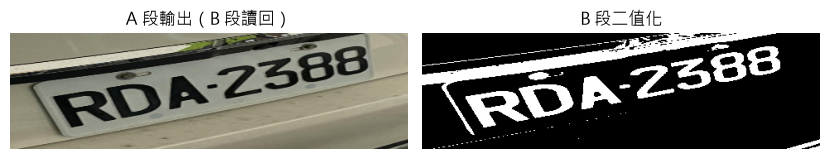

B 段完成 2 張


,stem,text,valid,conf,reason
0,train_IMG_1231_JPG.rf.4427265fe92179f31edca9a2...,,False,0.0,
1,train_IMG_1245_JPG.rf.a4ac20b643db2721c55399a1...,,False,0.0,



run_pipeline()：失敗 → 定位失敗：沒有任何候選四邊形｜text=''｜階段=['01_input', '02_pre', '03_localize']


In [35]:
# --- self test: [INT-02] B 段 ---
_stems = list_stage_stems()
print(f'A 段留下的 stem：{len(_stems)} 個')

if not _stems:
    print('尚無輸入 —— 需要先執行 [INT-01] 的 export_dataset_frontend()')
else:
    _one, _one_mask = load_stage(_stems[0])
    print(f'讀回 {_stems[0][:40]}… shape={None if _one is None else _one.shape}')

    _res = run_backend(_stems[0])
    print(f'B 段結果：text={_res["text"]!r}  valid={_res["valid"]}  conf={_res["conf"]:.2f}')
    if _res['reason']:
        print('  原因：', _res['reason'])

    # §6 還沒實作，所以 text 必然是空字串 —— 這代表「讀得到輸入，但還不會辨識」
    if _one is not None:
        show(_one, _res['binary'], titles=['A 段輸出（B 段讀回）', 'B 段二值化'], cols=2)

    _tab = run_dataset_backend(limit=5)
    if not _tab.empty:
        display(_tab)

# 完整流程（記憶體版）：A 段 + B 段一次跑完，供 §9 使用
_p = pick_sample_image()
if _p:
    _full = run_pipeline(load_image(_p), case_name='_selftest_int')
    _s = '成功' if _full['text'] or not _full['reason'] else f'失敗 → {_full["reason"]}'
    print(f'\nrun_pipeline()：{_s}｜text={_full["text"]!r}｜階段={list(_full["stages"])}')


## §9 評估（EV）

用 `data/labels.csv` 的標註跑完整 pipeline，計算每階段成功率、字元準確率與整體車牌準確率。

In [36]:
# ==== [EV-01] 全流程評估 ====
# 不可評分的難度標記：這些列的 text 沒有可靠答案，算進準確率只會製造假錯誤。
# 常數定義在 [S0-2]，此處保留舊名以免既有說明與報告對不上。
# 目前只有 #16（反光遮蔽、text 留空）屬於這一類，見 TASK_DIVISION.md §7。
EVAL_EXCLUDE_DIFFICULTY = UNSCORABLE_DIFFICULTIES


def evaluable_labels(df: Optional[pd.DataFrame] = None) -> pd.DataFrame:
    """回傳「有可靠標準答案、可以計入準確率」的列。

    🛠️ [開發用] TODO: 接口已預留、尚未實作 —— 實作 §9 時補上內容。
    預計行為：
      1. 讀 labels.csv（未給 df 時）
      2. 濾掉 difficulty 屬 EVAL_EXCLUDE_DIFFICULTY 的列
      3. 印出「總數 / 排除張數 / 有效樣本數」供報告引用
    現在先原樣回傳，避免其他章節呼叫時爆炸。
    """
    return load_labels() if df is None else df


def evaluate(limit: Optional[int] = None) -> pd.DataFrame:
    """對標註資料集跑完整 pipeline，回傳每張圖的結果與統計。"""
    if not os.path.exists(LABELS_CSV):
        print('尚未建立 labels.csv，略過評估')
        return pd.DataFrame()
    # 🛠️ [開發用] TODO: evaluable_labels() → run_pipeline → 比對 → 統計
    return pd.DataFrame()


In [37]:
# --- self test: [EV-01] ---
_df = evaluate(limit=2)
if _df.empty:
    print('尚無評估結果（需要 labels.csv 與可用的 pipeline）')
else:
    display(_df.head())


尚無評估結果（需要 labels.csv 與可用的 pipeline）
